### 1. Importing required libraries

In [1]:
# Importing Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import re
import string

from sklearn.model_selection import train_test_split

In [2]:
# Importing dataset 

fake = pd.read_csv("../data/Fake.csv")
real = pd.read_csv("../data/True.csv")


In [3]:
# Display the datasets

print("Fake News Dataset:")

display(fake.head())

print("Real News Dataset:")

display(real.head())

Fake News Dataset:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


Real News Dataset:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


### 2. Exploratory Data Analysis (EDA)

In [4]:
# Check dataset dimensions 
print("Fake News Shape:", fake.shape)
print("Real News Shape:", real.shape)

Fake News Shape: (23481, 4)
Real News Shape: (21417, 4)


In [5]:
# Checking names
print("Fake Dataset Columns:")
print(fake.columns)

print("\nReal Dataset Columns:")
print(real.columns)

Fake Dataset Columns:
Index(['title', 'text', 'subject', 'date'], dtype='str')

Real Dataset Columns:
Index(['title', 'text', 'subject', 'date'], dtype='str')


In [6]:
# Checking data types
print("Fake Dataset Information:")
fake.info()

print("\nReal Dataset Information:")
real.info()

Fake Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    23481 non-null  str  
 1   text     23481 non-null  str  
 2   subject  23481 non-null  str  
 3   date     23481 non-null  str  
dtypes: str(4)
memory usage: 60.4 MB

Real Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    21417 non-null  str  
 1   text     21417 non-null  str  
 2   subject  21417 non-null  str  
 3   date     21417 non-null  str  
dtypes: str(4)
memory usage: 51.6 MB


In [7]:
# Checking missing values 
print("Missing Values in Fake Dataset:")
print(fake.isnull().sum())

print("\nMissing Values in Real Dataset:")
print(real.isnull().sum())

Missing Values in Fake Dataset:
title      0
text       0
subject    0
date       0
dtype: int64

Missing Values in Real Dataset:
title      0
text       0
subject    0
date       0
dtype: int64


In [8]:
# Checking duplicate records

print("Fake Dataset Duplicates:", fake.duplicated().sum())

print("Real Dataset Duplicates:", real.duplicated().sum())

Fake Dataset Duplicates: 3
Real Dataset Duplicates: 206


In [9]:
# Statistical summary 

print("Fake Dataset Summary:")
display(fake.describe(include="all"))

print("Real Dataset Summary:")
display(real.describe(include="all"))

Fake Dataset Summary:


,title,text,subject,date
count,23481,23481,23481,23481
unique,17903,17455,6,1681
top,MEDIA IGNORES Time That Bill Clinton FIRED His...,,News,"May 10, 2017"
freq,6,626,9050,46


Real Dataset Summary:


,title,text,subject,date
count,21417,21417,21417,21417
unique,20826,21192,2,716
top,Factbox: Trump fills top jobs for his administ...,(Reuters) - Highlights for U.S. President Dona...,politicsNews,"December 20, 2017"
freq,14,8,11272,182


In [10]:
# Checking class distribution 

print("Fake News Count:", len(fake))
print("Real News Count:", len(real))

print("Total News Articles:", len(fake) + len(real))

Fake News Count: 23481
Real News Count: 21417
Total News Articles: 44898


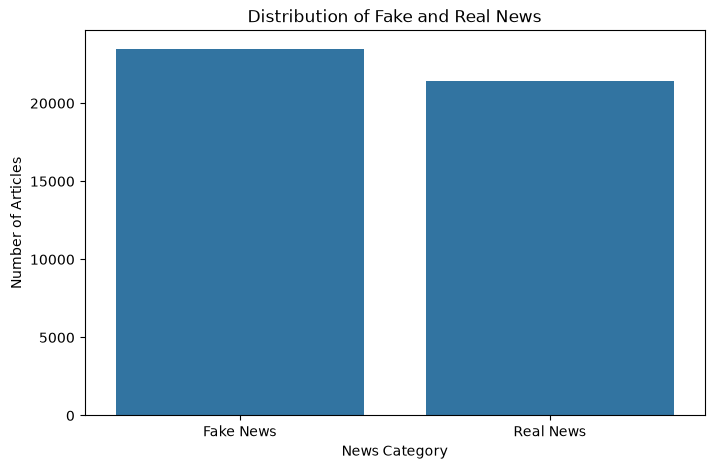

In [11]:
# Visualise dataset distribution

plt.figure(figsize=(8, 5))

sns.barplot(
    x=["Fake News", "Real News"],
    y=[len(fake), len(real)]
)

plt.title("Distribution of Fake and Real News")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")

plt.show()

### Data Cleaning and Preprocessing

#### Combining both datasets 

In [12]:
# Adding target labels
fake["label"] = 0
real["label"] = 1

In [13]:
# Combining datasets

df = pd.concat([fake, real], axis=0)

df = df.sample(frac=1, random_state=42)

df = df.reset_index(drop=True)

In [14]:
# Verifying combined dataset 

print("Dataset Shape:", df.shape)

print("\nLabel Distribution:")
print(df["label"].value_counts())

display(df.head())

Dataset Shape: (44898, 5)

Label Distribution:
label
0    23481
1    21417
Name: count, dtype: int64


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


#### Removing duplicate records

In [15]:
# Identifying duplicates

print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 209


In [16]:
# Removing Duplicates

df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("Shape After Removing Duplicates:", df.shape)

Shape After Removing Duplicates: (44689, 5)


#### Importing NLP Resources

In [17]:
# Downloading NLTK resources

import nltk

nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [18]:
# Importing preprocessing tools

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer

In [19]:
# Examine English stopwords

stop_words = set(stopwords.words("english"))

print("Total Stopwords:", len(stop_words))

print("Sample Stopwords:")

print(list(stop_words)[:30])

Total Stopwords: 198
Sample Stopwords:
['but', 'more', "he's", 're', 'above', 'do', 'same', 'o', 'should', 'is', "aren't", 'her', 'nor', 'am', 'won', "she's", "we'd", "they'll", 'him', 'haven', 'there', 'on', 'yourself', 'before', 'can', "couldn't", 'ain', 'you', "hasn't", 'ourselves']


#### Creating a text-cleaning function

In [20]:
# Defining preprocessing function 

import re
import string

stop_words = set(stopwords.words("english"))

negation_words = {"no", "nor", "not", "never"}

stop_words = stop_words - negation_words

stemmer = PorterStemmer()


def preprocess_text(text):

    text = str(text)

    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove numbers
    text = re.sub(r"\d+", "", text)

    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenization
    tokens = word_tokenize(text)

    # Stopword removal and stemming
    cleaned_tokens = [
        stemmer.stem(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return " ".join(cleaned_tokens)

In [21]:
# Regular Expressions

re.sub(r"\d+", "", "Breaking News 2026")

'Breaking News '

#### Testing our preprocessing function

In [22]:
# Test with sample text

# Check whether 
# Everything is lowercase.
# URLs are removed.
# Numbers are removed.
# Punctuation is removed.
# Negation words are preserved.
# Words are stemmed.

sample_text = """
THE Government Announces New Policies!!!
Visit https://example.com for details.
This is NOT a fake announcement in 2026.
"""

cleaned_text = preprocess_text(sample_text)

print("Original Text:")
print(sample_text)

print("\nCleaned Text:")
print(cleaned_text)

Original Text:

THE Government Announces New Policies!!!
Visit https://example.com for details.
This is NOT a fake announcement in 2026.


Cleaned Text:
govern announc new polici visit detail not fake announc


#### Applying preprocessing to our dataset

In [23]:
# Cleaning news articles

df["clean_text"] = df["text"].apply(preprocess_text)

In [24]:
# Comparing original and cleaned text

display(
    df[["text", "clean_text", "label"]].head(10)
)

,text,clean_text,label
0,"21st Century Wire says Ben Stein, reputable pr...",centuri wire say ben stein reput professor pep...,0
1,WASHINGTON (Reuters) - U.S. President Donald T...,washington reuter presid donald trump remov ch...,1
2,(Reuters) - Puerto Rico Governor Ricardo Rosse...,reuter puerto rico governor ricardo rossello s...,1
3,"On Monday, Donald Trump once again embarrassed...",monday donald trump embarrass countri accident...,0
4,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",glasgow scotland reuter presidenti candid abro...,1
5,"On Wednesday, Democrats took a powerful stance...",wednesday democrat took power stanc gop refus ...,0
6,President Trump s rally in FL on Saturday was ...,presid trump ralli saturday smash success crow...,0
7,He s been Europe s version of the outspoken Te...,europ version outspoken ted cruz time nigel fa...,0
8,WASHINGTON (Reuters) - The State Department sa...,washington reuter state depart said wednesday ...,1
9,(This version of the story corrects the figur...,version stori correct figur current minimum wa...,1


In [25]:
# Checking for empty cleaned articles

print(
    "Empty Cleaned Articles:",
    (df["clean_text"].str.strip() == "").sum()
)

Empty Cleaned Articles: 716


In [26]:
# Investigating empty articles 

empty_articles = df[df["clean_text"].str.strip() == ""]

print("Empty Articles:", len(empty_articles))

display(empty_articles[["title", "text", "label"]].head(10))

Empty Articles: 716


,title,text,label
11,WHERE’S HILLARY? CLINTON SPOTTED Dining Alone,,0
41,WHOA! RUSH LIMBAUGH RIPS Into Republicans Who ...,,0
177,HILLARY TAKES CREDIT For The Arab Spring Disas...,,0
324,CHILLING! FOX REPORTER JAMES ROSEN Recounts Be...,,0
400,LIVE FEED: INAUGURATION 2017!,,0
407,UNREAL! CNN PANEL Laughs And Mocks Dr. Ben Car...,https://www.youtube.com/watch?v=_FNt3ns_EGA,0
424,WHICH ONE OF THESE PEOPLE Tried to Lecture the...,,0
431,UNREAL! OBAMA BLAMES SYRIAN CIVIL WAR ON CLIMA...,,0
458,MICHAEL FLYNN’S LAWYER Releases Statement Scor...,,0
491,BOOM! JULIAN ASSANGE OF WIKILEAKS Drops A Trut...,,0


In [27]:
# Checking original text lengths

empty_articles = empty_articles.copy()

empty_articles["original_length"] = (
    empty_articles["text"].astype(str).str.len()
)

display(empty_articles["original_length"].describe())

count    716.000000
mean       6.579609
std       16.569770
min        1.000000
25%        1.000000
50%        1.000000
75%        1.000000
max      149.000000
Name: original_length, dtype: float64

In [28]:
# Examine examples 

for i, row in empty_articles.head(5).iterrows():

    print("Title:", row["title"])
    print("Original Text:", repr(row["text"]))
    print("Label:", row["label"])
    print("-" * 80)

Title: WHERE’S HILLARY? CLINTON SPOTTED Dining Alone
Original Text: ' '
Label: 0
--------------------------------------------------------------------------------
Title: WHOA! RUSH LIMBAUGH RIPS Into Republicans Who Don’t Support Trump [Audio]
Original Text: ' '
Label: 0
--------------------------------------------------------------------------------
Title: HILLARY TAKES CREDIT For The Arab Spring Disaster…AND SHE WANTS TO BE PRESIDENT?
Original Text: ' '
Label: 0
--------------------------------------------------------------------------------
Title: CHILLING! FOX REPORTER JAMES ROSEN Recounts Being Spied on by the Obama Mafia [Video]
Original Text: ' '
Label: 0
--------------------------------------------------------------------------------
Title: LIVE FEED: INAUGURATION 2017!
Original Text: ' '
Label: 0
--------------------------------------------------------------------------------


In [29]:
# Removing empty cleaned articles 

df = df[df["clean_text"].str.strip() != ""].copy()

df = df.reset_index(drop=True)

print("Dataset Shape After Removing Empty Articles:", df.shape)

print("Remaining Empty Articles:",
      (df["clean_text"].str.strip() == "").sum())

Dataset Shape After Removing Empty Articles: (43973, 6)
Remaining Empty Articles: 0


In [30]:
# Check updated class distribution 

print(df["label"].value_counts())

print("\nClass Distribution (%):")

print(df["label"].value_counts(normalize=True) * 100)

label
0    22763
1    21210
Name: count, dtype: int64

Class Distribution (%):
label
0    51.765856
1    48.234144
Name: proportion, dtype: float64


### 4. Feature Engineering using NLP 

#### Practical implementation 

In [31]:
# Creating sample documents

documents = [
    "machine learning is interesting",
    "machine learning is powerful",
    "python is interesting"
]

print(documents)

['machine learning is interesting', 'machine learning is powerful', 'python is interesting']


In [32]:
# Applying bag of words

from sklearn.feature_extraction.text import CountVectorizer

bow = CountVectorizer()

bow_matrix = bow.fit_transform(documents)

print("Vocabulary:")
print(bow.get_feature_names_out())

print("\nDocument Term Matrix:")
print(bow_matrix.toarray())

Vocabulary:
['interesting' 'is' 'learning' 'machine' 'powerful' 'python']

Document Term Matrix:
[[1 1 1 1 0 0]
 [0 1 1 1 1 0]
 [1 1 0 0 0 1]]


In [33]:
# Applying TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

tfidf_matrix = tfidf.fit_transform(documents)

print("Vocabulary:")
print(tfidf.get_feature_names_out())

print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray())

Vocabulary:
['interesting' 'is' 'learning' 'machine' 'powerful' 'python']

TF-IDF Matrix:
[[0.52682017 0.40912286 0.52682017 0.52682017 0.         0.        ]
 [0.         0.37311881 0.4804584  0.4804584  0.63174505 0.        ]
 [0.54783215 0.42544054 0.         0.         0.         0.72033345]]


In [34]:
# Understand matrix dimensions

print("BoW Matrix Shape:", bow_matrix.shape)

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

BoW Matrix Shape: (3, 6)
TF-IDF Matrix Shape: (3, 6)


#### Applying TF-IDF to our actual news dataset

In [35]:
# Preparing input and target variables 

X = df["clean_text"]

y = df["label"]

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Shape: (43973,)
Target Shape: (43973,)


In [36]:
# Train-test splitting

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [37]:
# Verifying the split 

print("Training Samples:", X_train.shape[0])

print("Testing Samples:", X_test.shape[0])

print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Samples: 35178
Testing Samples: 8795

Training Class Distribution:
label
0    51.765308
1    48.234692
Name: proportion, dtype: float64

Testing Class Distribution:
label
0    51.76805
1    48.23195
Name: proportion, dtype: float64


In [38]:
# TF-IDF implementation 

# Initializeing TD-IDF Vectorizer 

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

In [39]:
# Fit and transform training data

X_train_tfidf = tfidf.fit_transform(X_train)

In [40]:
# Transform testing data 

X_test_tfidf = tfidf.transform(X_test)

#### Examining the TF-IDF matrices 

In [41]:
# Check matrix dimensions

print("Training TF-IDF Shape:", X_train_tfidf.shape)

print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (35178, 20000)
Testing TF-IDF Shape: (8795, 20000)


In [42]:
# Inspecting vocabulary

print("Total Vocabulary Size:", len(tfidf.vocabulary_))

print("\nFirst 30 Vocabulary Words:")

print(list(tfidf.vocabulary_.keys())[:30])

Total Vocabulary Size: 20000

First 30 Vocabulary Words:
['secret', 'bill', 'maher', 'comedian', 'host', 'hbo', 'real', 'time', 'fan', 'gop', 'presidenti', 'nomine', 'donald', 'trump', 'cours', 'resist', 'live', 'tweet', 'entir', 'first', 'gener', 'elect', 'debat', 'democrat', 'hillari', 'clinton', 'whole', 'thing', 'one', 'brilliant']


In [43]:
# Inspecting numerical representation

print("First Training Article:")

print(X_train.iloc[0])

print("\nCorresponding TF-IDF Vector:")

print(X_train_tfidf[0].toarray())

First Training Article:
secret bill maher comedian extraordinair host hbo real time fan gop presidenti nomine donald trump cours resist live tweet entir first gener elect presidenti debat trump democrat nomine hillari clinton whole thing one brilliant insult trump anoth better tweetsgop expect game nomin orangutan long doesnt fling poop surprisingli dignifi trump last night bill maher billmah septemb want see hillari come say russian hand tax return see trump bolt bill maher billmah septemb trump adjust spanx right one final pass final net bill maher billmah septemb trump proud call secretari clinton oppos bitchula bill maher billmah septemb trump wear tie made china sayin bill maher billmah septemb oki hope she play ropeadop mean dope get tire vile nincompoop bulli lie earli bill maher billmah septemb trump iraq disast shld take oilw wld back iraq take oil wont give drone bill maher billmah septemb btw know charg agst trump provabl true interrupt wrong debat bill maher billmah septemb

In [44]:
# Displaying top TF-IDF features 

feature_names = tfidf.get_feature_names_out()

article_vector = X_train_tfidf[0].toarray().flatten()

top_indices = article_vector.argsort()[-20:][::-1]

for index in top_indices:
    print(
        feature_names[index],
        article_vector[index]
    )

maher 0.3187433332174899
bill maher 0.3161475478746453
septemb trump 0.23654015808266854
septemb 0.17216132321284425
bill 0.13453076757761817
tonight 0.11132868284122924
say russian 0.09886014856208142
there 0.09834701034745683
let face 0.09834701034745683
trump surrog 0.09834701034745683
dignifi 0.09785324052627128
hbo 0.09785324052627128
come say 0.09714586028859142
wont 0.09691831807717112
nomine 0.09671120838321817
way around 0.09604577165744223
nomine would 0.09583643363342903
way one 0.09542754575029701
trump cours 0.09503105033541681
uneduc 0.09503105033541681


In [45]:
# Verifying the TF-IDF dimensions 

print("Training Matrix:", X_train_tfidf.shape)
print("Testing Matrix:", X_test_tfidf.shape)

print("Number of Features:", len(feature_names))

Training Matrix: (35178, 20000)
Testing Matrix: (8795, 20000)
Number of Features: 20000


### 5. Machine Learning Model Development

#### 1. Logistic Regression

In [46]:
# Importing the algorithm
from sklearn.linear_model import LogisticRegression

In [47]:
# Initializing the model

log_reg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [48]:
# Training the model 
log_reg.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [49]:
# Generating predictions  
y_pred_lr = log_reg.predict(X_test_tfidf)

In [50]:
# Inspecting the first 20 predictions 

print("Actual Labels:")
print(y_test.iloc[:20].values)

print("\nPredicted Labels:")
print(y_pred_lr[:20])

Actual Labels:
[0 1 1 1 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1]

Predicted Labels:
[0 1 1 1 0 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1]


#### Evaluating Logistic Regression

In [51]:
# Importing evaluation metrics 

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [52]:
# Calculating evaluation metrics

accuracy = accuracy_score(y_test, y_pred_lr)

precision = precision_score(y_test, y_pred_lr)

recall = recall_score(y_test, y_pred_lr)

f1 = f1_score(y_test, y_pred_lr)

print("Logistic Regression Performance")

print("Accuracy :", accuracy)

print("Precision:", precision)

print("Recall   :", recall)

print("F1 Score :", f1)

Logistic Regression Performance
Accuracy : 0.9922683342808414
Precision: 0.9903665413533834
Recall   : 0.9936350777934936
F1 Score : 0.991998117204048


In [53]:
# Generating confusion matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[4512   41]
 [  27 4215]]


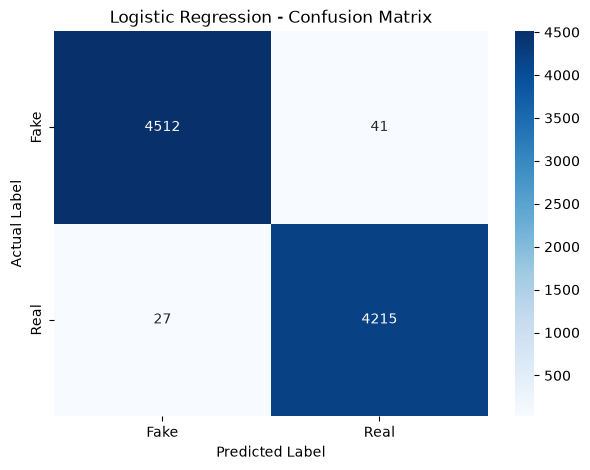

In [54]:
# Visualising confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [55]:
# Classification report 

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["Fake News", "Real News"]
    )
)

              precision    recall  f1-score   support

   Fake News       0.99      0.99      0.99      4553
   Real News       0.99      0.99      0.99      4242

    accuracy                           0.99      8795
   macro avg       0.99      0.99      0.99      8795
weighted avg       0.99      0.99      0.99      8795



In [56]:
# Obtaining exact metric values

print(f"Accuracy:  {accuracy_score(y_test, y_pred_lr):.6f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.6f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr):.6f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_lr):.6f}")

Accuracy:  0.992268
Precision: 0.990367
Recall:    0.993635
F1 Score:  0.991998


### 2. Multinomial Naive Bayes

In [57]:
# Importing algorithm 

from sklearn.naive_bayes import MultinomialNB

In [58]:
# Initializing Model 

nb_model = MultinomialNB(alpha=1.0)

In [59]:
# Training model 

nb_model.fit(X_train_tfidf, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[18210.,16968.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.66,-0.73]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 20000)","[[ 9.77, 0.08,17.56,..., 1.4 , 7.18, 0. ], [ 2.01,11.34,23.89,..., 3.65, 2.58,15.93]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 20000)","[[ -9.96,-12.26, -9.41,...,-11.46,-10.23,-12.34], [-11.2 , -9.79, -9.08,...,-10.76,-11.02, -9.47]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,20000


In [60]:
# Generating predictions

y_pred_nb = nb_model.predict(X_test_tfidf)

In [61]:
# Evaluating model

print("Multinomial Naive Bayes Performance")

print("Accuracy:",
      accuracy_score(y_test, y_pred_nb))

print("Precision:",
      precision_score(y_test, y_pred_nb))

print("Recall:",
      recall_score(y_test, y_pred_nb))

print("F1 Score:",
      f1_score(y_test, y_pred_nb))

Multinomial Naive Bayes Performance
Accuracy: 0.9564525298465036
Precision: 0.9538932015996237
Recall: 0.9559170202734559
F1 Score: 0.95490403862004


In [62]:
# Classification report

print(
    classification_report(
        y_test,
        y_pred_nb,
        target_names=["Fake News", "Real News"]
    )
)

              precision    recall  f1-score   support

   Fake News       0.96      0.96      0.96      4553
   Real News       0.95      0.96      0.95      4242

    accuracy                           0.96      8795
   macro avg       0.96      0.96      0.96      8795
weighted avg       0.96      0.96      0.96      8795



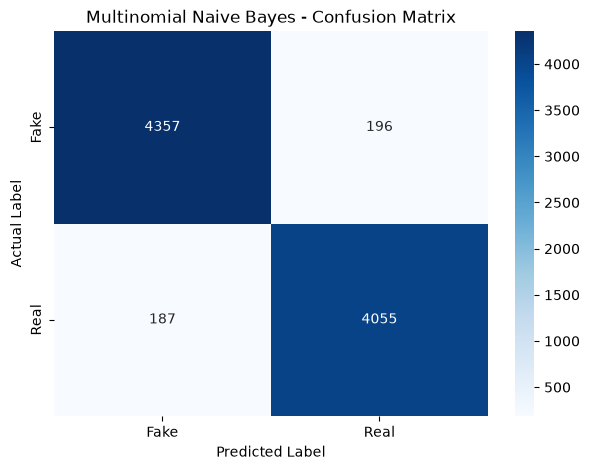

In [63]:
# Confusion matrix

cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Multinomial Naive Bayes - Confusion Matrix")

plt.show()

#### Comparing our first two algorithms

In [64]:
# Model comparison 

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_nb)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_nb)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_nb)
    ]
})

display(model_comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.992268,0.990367,0.993635,0.991998
1,Multinomial Naive Bayes,0.956453,0.953893,0.955917,0.954904


#### 3. Passive Aggressive Classifier

In [65]:
# Importing algorithm 

from sklearn.linear_model import PassiveAggressiveClassifier

In [66]:
# Initializing model

pa_model = PassiveAggressiveClassifier(
    C=1.0,
    max_iter=1000,
    random_state=42,
    tol=1e-3
)

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\deprecation.py:71: FutureWarning: Class PassiveAggressiveClassifier is deprecated; this is deprecated in version 1.8 and will be removed in 1.10. Use `SGDClassifier(loss='hinge', penalty=None, learning_rate='pa1', eta0=1.0)` instead.
  warnings.warn(msg, category=FutureWarning)


In [67]:
# Training model 
pa_model.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Aggressiveness parameter for the passive-aggressive algorithm, see [1].For PA-I it is the maximum step size. For PA-II it regularizes thestep size (the smaller `C` the more it regularizes).As a general rule-of-thumb, `C` should be small when the data is noisy.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`~sklearn.linear_model.PassiveAggressiveClassifier.partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically set asidea stratified fraction of training data as validation and terminatetraining when validation score is not improving by at least `tol` for`n_iter_no_change` consecutive epochs... versionadded:: 0.20",False
,"validation_fraction validation_fraction: float, default=0.1The proportion of training data to set aside as validation set forearly stopping. Must be between 0 and 1.Only used if early_stopping is True... versionadded:: 0.20",0.1
,"n_iter_no_change n_iter_no_change: int, default=5Number of iterations with no improvement to wait before early stopping... versionadded:: 0.20",5
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"loss loss: str, default=""hinge""The loss function to be used:hinge: equivalent to PA-I in the reference paper.squared_hinge: equivalent to PA-II in the reference paper.",'hinge'


In [68]:
# Generating predictions 
y_pred_pa = pa_model.predict(X_test_tfidf)

In [69]:
# Evaluating performance 

print("Passive Aggressive Classifier Performance")

print("Accuracy:",
      accuracy_score(y_test, y_pred_pa))

print("Precision:",
      precision_score(y_test, y_pred_pa))

print("Recall:",
      recall_score(y_test, y_pred_pa))

print("F1 Score:",
      f1_score(y_test, y_pred_pa))

Passive Aggressive Classifier Performance
Accuracy: 0.9976122797043775
Precision: 0.9976420655505777
Recall: 0.9974068835454974
F1 Score: 0.997524460686078


In [70]:
# Classification report

print(
    classification_report(
        y_test,
        y_pred_pa,
        target_names=["Fake News", "Real News"]
    )
)

              precision    recall  f1-score   support

   Fake News       1.00      1.00      1.00      4553
   Real News       1.00      1.00      1.00      4242

    accuracy                           1.00      8795
   macro avg       1.00      1.00      1.00      8795
weighted avg       1.00      1.00      1.00      8795



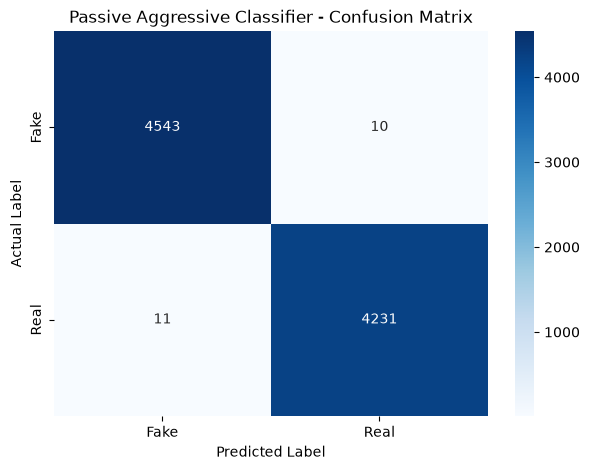

In [71]:
# Confusion matrix

cm_pa = confusion_matrix(y_test, y_pred_pa)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_pa,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("Passive Aggressive Classifier - Confusion Matrix")

plt.show()

#### Comparing all three algorithms

In [72]:
# Updated comparison table 

model_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes",
        "Passive Aggressive"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_pa)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_pa)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_pa)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_pa)
    ]
})

display(
    model_comparison.sort_values(
        by="F1 Score",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Passive Aggressive,0.997612,0.997642,0.997407,0.997524
1,Logistic Regression,0.992268,0.990367,0.993635,0.991998
2,Multinomial Naive Bayes,0.956453,0.953893,0.955917,0.954904


#### 4. Decision Tree Classifier

In [73]:
# Importing the algorithm 

from sklearn.tree import DecisionTreeClassifier

In [74]:
# Initializing the model 

dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=100,
    min_samples_split=2,
    random_state=42
)

In [75]:
# Training the model 
dt_model.fit(X_train_tfidf, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

In [76]:
# Genrating predictions

y_pred_dt = dt_model.predict(X_test_tfidf)

In [77]:
# Evaluating performance

print("Decision Tree Performance")

print("Accuracy:",
      accuracy_score(y_test, y_pred_dt))

print("Precision:",
      precision_score(y_test, y_pred_dt))

print("Recall:",
      recall_score(y_test, y_pred_dt))

print("F1 Score:",
      f1_score(y_test, y_pred_dt))

Decision Tree Performance
Accuracy: 0.995224559408755
Precision: 0.9969238050165641
Recall: 0.9931636020744932
F1 Score: 0.995040151157298


In [78]:
# Classification report

print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=["Fake News", "Real News"]
    )
)

              precision    recall  f1-score   support

   Fake News       0.99      1.00      1.00      4553
   Real News       1.00      0.99      1.00      4242

    accuracy                           1.00      8795
   macro avg       1.00      1.00      1.00      8795
weighted avg       1.00      1.00      1.00      8795



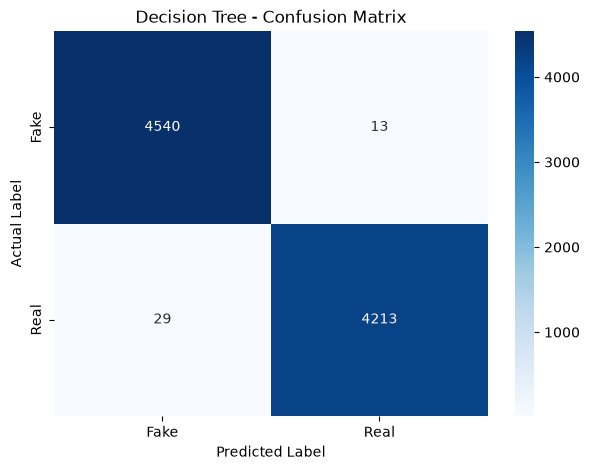

In [79]:
# Confusion matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("Decision Tree - Confusion Matrix")

plt.show()


In [80]:
# Understanding overfitting using training performance 

# Compare training and testing accuracy

train_accuracy_dt = accuracy_score(
    y_train,
    dt_model.predict(X_train_tfidf)
)

test_accuracy_dt = accuracy_score(
    y_test,
    y_pred_dt
)

print("Training Accuracy:", train_accuracy_dt)

print("Testing Accuracy:", test_accuracy_dt)

Training Accuracy: 1.0
Testing Accuracy: 0.995224559408755


#### Updating model comparison

In [81]:
model_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes",
        "Passive Aggressive",
        "Decision Tree"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_pa),
        accuracy_score(y_test, y_pred_dt)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_pa),
        precision_score(y_test, y_pred_dt)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_pa),
        recall_score(y_test, y_pred_dt)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_pa),
        f1_score(y_test, y_pred_dt)
    ]
})

display(
    model_comparison.sort_values(
        by="F1 Score",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Passive Aggressive,0.997612,0.997642,0.997407,0.997524
1,Decision Tree,0.995225,0.996924,0.993164,0.995040
2,Logistic Regression,0.992268,0.990367,0.993635,0.991998
3,Multinomial Naive Bayes,0.956453,0.953893,0.955917,0.954904


### 5. Random Forest Classifier

In [82]:
# Importing the algorithm

from sklearn.ensemble import RandomForestClassifier

In [83]:
# Initializing the model

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=50,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

In [84]:
# Training the model 

rf_model.fit(X_train_tfidf, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",50
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

In [85]:
# Generating predictions

y_pred_rf = rf_model.predict(X_test_tfidf)

In [86]:
# Evaluating performance

print("Random Forest Performance")

print("Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("Precision:",
      precision_score(y_test, y_pred_rf))

print("Recall:",
      recall_score(y_test, y_pred_rf))

print("F1 Score:",
      f1_score(y_test, y_pred_rf))

Random Forest Performance
Accuracy: 0.9964752700397953
Precision: 0.9971664698937426
Recall: 0.9955209806694956
F1 Score: 0.9963430458888758


In [87]:
# Classification report

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Fake News", "Real News"]
    )
)

              precision    recall  f1-score   support

   Fake News       1.00      1.00      1.00      4553
   Real News       1.00      1.00      1.00      4242

    accuracy                           1.00      8795
   macro avg       1.00      1.00      1.00      8795
weighted avg       1.00      1.00      1.00      8795



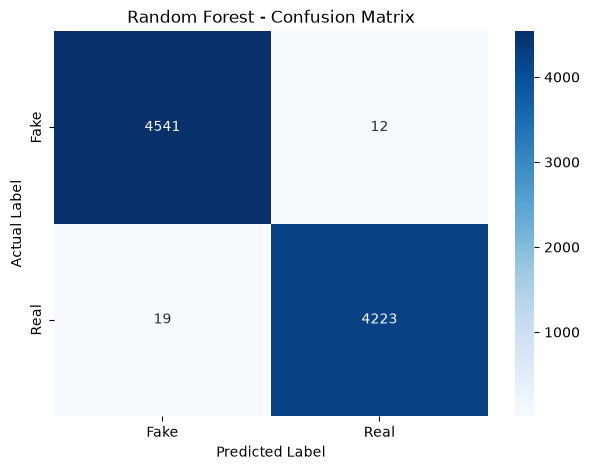

In [88]:
# Confusion matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("Random Forest - Confusion Matrix")

plt.show()

#### Comparing Training and testing performance

In [89]:
train_accuracy_rf = accuracy_score(
    y_train,
    rf_model.predict(X_train_tfidf)
)

test_accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print("Training Accuracy:", train_accuracy_rf)

print("Testing Accuracy:", test_accuracy_rf)

Training Accuracy: 1.0
Testing Accuracy: 0.9964752700397953


#### Update our five-model comparison

In [90]:
model_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes",
        "Passive Aggressive",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_pa),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_pa),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_pa),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_pa),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})

display(
    model_comparison.sort_values(
        by="F1 Score",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Passive Aggressive,0.997612,0.997642,0.997407,0.997524
1,Random Forest,0.996475,0.997166,0.995521,0.996343
2,Decision Tree,0.995225,0.996924,0.993164,0.995040
3,Logistic Regression,0.992268,0.990367,0.993635,0.991998
4,Multinomial Naive Bayes,0.956453,0.953893,0.955917,0.954904


#### 6. Support Vector Machine (SVM)

In [91]:
# Importing the algorithm 

from sklearn.svm import LinearSVC

In [92]:
# Initializing the model

svm_model = LinearSVC(
    C=1.0,
    max_iter=2000,
    random_state=42
)

In [93]:
# Training the model
svm_model.fit(X_train_tfidf, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",2000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are su

In [94]:
# Generating predictions
y_pred_svm = svm_model.predict(X_test_tfidf)


In [95]:
# Evaluating performance

print("Linear SVM Performance")

print("Accuracy:",
      accuracy_score(y_test, y_pred_svm))

print("Precision:",
      precision_score(y_test, y_pred_svm))

print("Recall:",
      recall_score(y_test, y_pred_svm))

print("F1 Score:",
      f1_score(y_test, y_pred_svm))

Linear SVM Performance
Accuracy: 0.9976122797043775
Precision: 0.9969390157758418
Recall: 0.9981140971239981
F1 Score: 0.9975262103899164


In [96]:
# Classification report

print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=["Fake News", "Real News"]
    )
)

              precision    recall  f1-score   support

   Fake News       1.00      1.00      1.00      4553
   Real News       1.00      1.00      1.00      4242

    accuracy                           1.00      8795
   macro avg       1.00      1.00      1.00      8795
weighted avg       1.00      1.00      1.00      8795



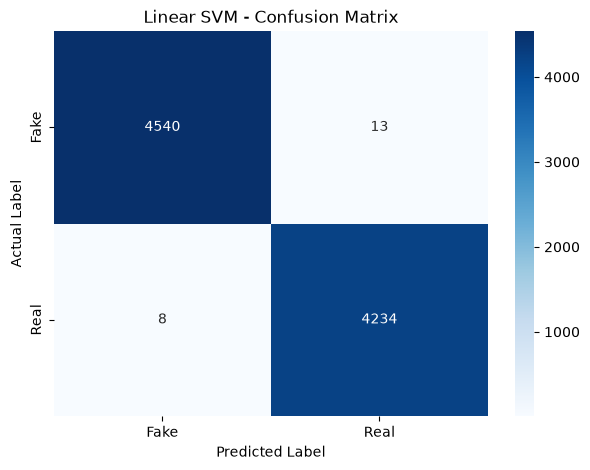

In [97]:
# Confusion matrix

cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("Linear SVM - Confusion Matrix")

plt.show()

#### Comparing training and testing accuracy

In [98]:
train_accuracy_svm = accuracy_score(
    y_train,
    svm_model.predict(X_train_tfidf)
)

test_accuracy_svm = accuracy_score(
    y_test,
    y_pred_svm
)

print("Training Accuracy:", train_accuracy_svm)

print("Testing Accuracy:", test_accuracy_svm)

Training Accuracy: 0.9999147194269146
Testing Accuracy: 0.9976122797043775


#### All six algorithms - final comparison

In [99]:
model_comparison = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Multinomial Naive Bayes",
        "Passive Aggressive",
        "Decision Tree",
        "Random Forest",
        "Linear SVM"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_pa),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_svm)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_nb),
        precision_score(y_test, y_pred_pa),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_svm)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_nb),
        recall_score(y_test, y_pred_pa),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_svm)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_nb),
        f1_score(y_test, y_pred_pa),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_svm)
    ]
})

model_comparison = model_comparison.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(model_comparison)

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.997612,0.996939,0.998114,0.997526
1,Passive Aggressive,0.997612,0.997642,0.997407,0.997524
2,Random Forest,0.996475,0.997166,0.995521,0.996343
3,Decision Tree,0.995225,0.996924,0.993164,0.995040
4,Logistic Regression,0.992268,0.990367,0.993635,0.991998
5,Multinomial Naive Bayes,0.956453,0.953893,0.955917,0.954904


### Advanced Model Evaluation

In [100]:
# Generating Prediction Scores

y_scores = {
    "Logistic Regression": log_reg.predict_proba(X_test_tfidf)[:, 1],

    "Multinomial Naive Bayes": nb_model.predict_proba(X_test_tfidf)[:, 1],

    "Passive Aggressive": pa_model.decision_function(X_test_tfidf),

    "Decision Tree": dt_model.predict_proba(X_test_tfidf)[:, 1],

    "Random Forest": rf_model.predict_proba(X_test_tfidf)[:, 1],

    "Linear SVM": svm_model.decision_function(X_test_tfidf)
}

In [101]:
# Calculating ROC-AUC

from sklearn.metrics import roc_auc_score

roc_auc_results = {}

for model_name, scores in y_scores.items():

    auc = roc_auc_score(y_test, scores)

    roc_auc_results[model_name] = auc

    print(f"{model_name}: {auc:.6f}")

Logistic Regression: 0.999641
Multinomial Naive Bayes: 0.990492
Passive Aggressive: 0.999943
Decision Tree: 0.995154
Random Forest: 0.999892
Linear SVM: 0.999952


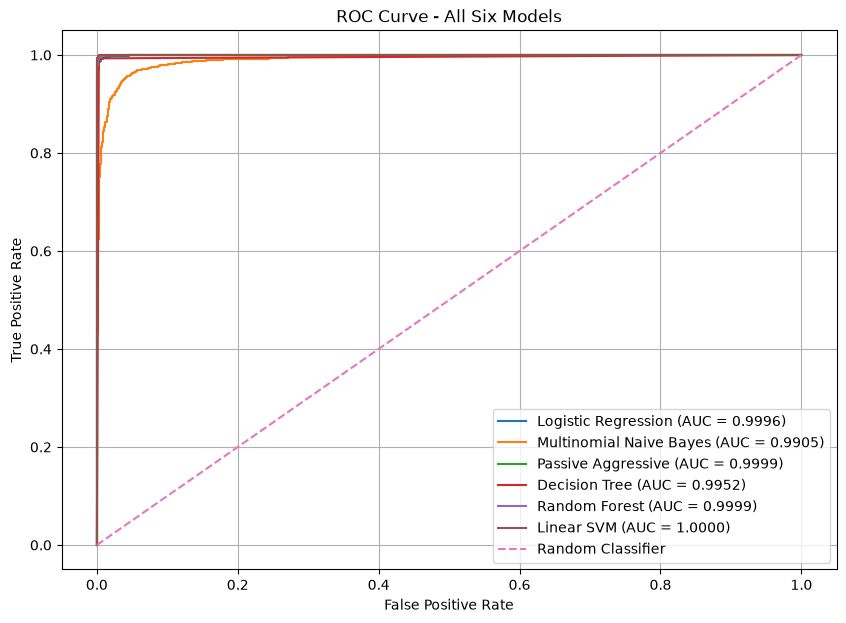

In [102]:
# Plotting ROC curves

from sklearn.metrics import roc_curve

plt.figure(figsize=(10, 7))

for model_name, scores in y_scores.items():

    fpr, tpr, thresholds = roc_curve(y_test, scores)

    auc = roc_auc_score(y_test, scores)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve - All Six Models")

plt.legend()

plt.grid()

plt.show()

#### Analyzing ROC-AUC Results

In [103]:
# Creating ROC-AUC comparison table

roc_auc_df = pd.DataFrame(
    list(roc_auc_results.items()),
    columns=["Model", "ROC-AUC"]
)

roc_auc_df = roc_auc_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(roc_auc_df)

,Model,ROC-AUC
0,Linear SVM,0.999952
1,Passive Aggressive,0.999943
2,Random Forest,0.999892
3,Logistic Regression,0.999641
4,Decision Tree,0.995154
5,Multinomial Naive Bayes,0.990492


#### Precision - Recall Curve

In [104]:
# Importing required metrics

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

In [105]:
# Calculating Average Precision

ap_results = {}

for model_name, scores in y_scores.items():

    ap = average_precision_score(y_test, scores)

    ap_results[model_name] = ap

    print(f"{model_name}: {ap:.6f}")

Logistic Regression: 0.999620
Multinomial Naive Bayes: 0.990073
Passive Aggressive: 0.999937
Decision Tree: 0.993406
Random Forest: 0.999878
Linear SVM: 0.999947


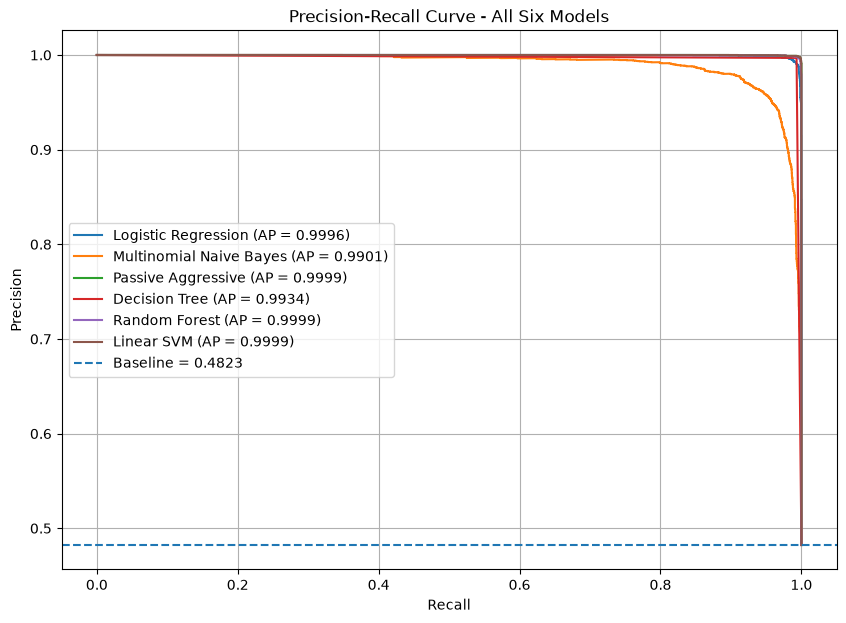

In [106]:
# Plotting Precision-Recall curves

plt.figure(figsize=(10, 7))

for model_name, scores in y_scores.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        scores
    )

    ap = average_precision_score(y_test, scores)

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP = {ap:.4f})"
    )

baseline = y_test.mean()

plt.axhline(
    y=baseline,
    linestyle="--",
    label=f"Baseline = {baseline:.4f}"
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title("Precision-Recall Curve - All Six Models")

plt.legend()

plt.grid()

plt.show()

In [107]:
# Creating AP comparison table

ap_df = pd.DataFrame(
    list(ap_results.items()),
    columns=["Model", "Average Precision"]
)

ap_df = ap_df.sort_values(
    by="Average Precision",
    ascending=False
).reset_index(drop=True)

display(ap_df)

,Model,Average Precision
0,Linear SVM,0.999947
1,Passive Aggressive,0.999937
2,Random Forest,0.999878
3,Logistic Regression,0.999620
4,Decision Tree,0.993406
5,Multinomial Naive Bayes,0.990073


#### Final Evaluation Table

In [108]:
final_evaluation = model_comparison.copy()

final_evaluation["ROC-AUC"] = (
    final_evaluation["Model"].map(roc_auc_results)
)

final_evaluation["Average Precision"] = (
    final_evaluation["Model"].map(ap_results)
)

display(
    final_evaluation.sort_values(
        by="Average Precision",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Linear SVM,0.997612,0.996939,0.998114,0.997526,0.999952,0.999947
1,Passive Aggressive,0.997612,0.997642,0.997407,0.997524,0.999943,0.999937
2,Random Forest,0.996475,0.997166,0.995521,0.996343,0.999892,0.999878
3,Logistic Regression,0.992268,0.990367,0.993635,0.991998,0.999641,0.999620
4,Decision Tree,0.995225,0.996924,0.993164,0.995040,0.995154,0.993406
5,Multinomial Naive Bayes,0.956453,0.953893,0.955917,0.954904,0.990492,0.990073


### Cross - Validation

In [109]:
# Importing libraries

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

In [110]:
# Defining cross-validation strategy

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [111]:
# Creating Linear SVM pipeline

svm_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LinearSVC(
            C=1.0,
            max_iter=2000,
            random_state=42
        )
    )
])

In [112]:
# Defining evaluation metrics

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

#### Linear SVM cross-validation

In [113]:
svm_cv_results = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    return_train_score=True,
    n_jobs=1
)

In [114]:
# Displaying fold results

svm_cv_df = pd.DataFrame({
    "Accuracy": svm_cv_results["test_accuracy"],
    "Precision": svm_cv_results["test_precision"],
    "Recall": svm_cv_results["test_recall"],
    "F1 Score": svm_cv_results["test_f1"],
    "ROC-AUC": svm_cv_results["test_roc_auc"],
    "Average Precision": svm_cv_results["test_average_precision"]
})

display(svm_cv_df)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,0.997442,0.997055,0.997643,0.997349,0.999788,0.999780
1,0.995452,0.994994,0.995580,0.995287,0.999817,0.999791
2,0.995736,0.993545,0.997643,0.995590,0.999804,0.999779
3,0.996588,0.995004,0.997937,0.996469,0.999649,0.999537
4,0.996162,0.995875,0.996169,0.996022,0.999842,0.999847


In [115]:
# Calculating mean and standard deviation

svm_cv_summary = pd.DataFrame({
    "Metric": scoring.keys(),

    "Mean": [
        svm_cv_results["test_accuracy"].mean(),
        svm_cv_results["test_precision"].mean(),
        svm_cv_results["test_recall"].mean(),
        svm_cv_results["test_f1"].mean(),
        svm_cv_results["test_roc_auc"].mean(),
        svm_cv_results["test_average_precision"].mean()
    ],

    "Standard Deviation": [
        svm_cv_results["test_accuracy"].std(),
        svm_cv_results["test_precision"].std(),
        svm_cv_results["test_recall"].std(),
        svm_cv_results["test_f1"].std(),
        svm_cv_results["test_roc_auc"].std(),
        svm_cv_results["test_average_precision"].std()
    ]
})

display(svm_cv_summary)

,Metric,Mean,Standard Deviation
0,accuracy,0.996276,0.000699
1,precision,0.995295,0.001155
2,recall,0.996994,0.000939
3,f1,0.996143,0.000723
4,roc_auc,0.999780,0.000068
5,average_precision,0.999747,0.000108


#### Passive Aggressive Cross - Validation

In [116]:
# Creating Passive Aggressive pipeline

pa_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        PassiveAggressiveClassifier(
            C=1.0,
            max_iter=1000,
            random_state=42,
            tol=1e-3
        )
    )
])

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\deprecation.py:71: FutureWarning: Class PassiveAggressiveClassifier is deprecated; this is deprecated in version 1.8 and will be removed in 1.10. Use `SGDClassifier(loss='hinge', penalty=None, learning_rate='pa1', eta0=1.0)` instead.
  warnings.warn(msg, category=FutureWarning)


In [117]:
# Running cross-validation

pa_cv_results = cross_validate(
    pa_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    return_train_score=True,
    n_jobs=1
)

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\deprecation.py:71: FutureWarning: Class PassiveAggressiveClassifier is deprecated; this is deprecated in version 1.8 and will be removed in 1.10. Use `SGDClassifier(loss='hinge', penalty=None, learning_rate='pa1', eta0=1.0)` instead.
  warnings.warn(msg, category=FutureWarning)
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\deprecation.py:71: FutureWarning: Class PassiveAggressiveClassifier is deprecated; this is deprecated in version 1.8 and will be removed in 1.10. Use `SGDClassifier(loss='hinge', penalty=None, learning_rate='pa1', eta0=1.0)` instead.
  warnings.warn(msg, category=FutureWarning)
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\deprecation.py:71: FutureWarning: Class PassiveAggressiveClassifier is deprecated; this is deprecated in version 1.8 and will be removed in 1.10. Use `SGDClassifier(loss='hinge', penal

In [118]:
# Comparing both algorithms

cv_comparison = pd.DataFrame({

    "Model": [
        "Linear SVM",
        "Passive Aggressive"
    ],

    "Mean Accuracy": [
        svm_cv_results["test_accuracy"].mean(),
        pa_cv_results["test_accuracy"].mean()
    ],

    "Mean Precision": [
        svm_cv_results["test_precision"].mean(),
        pa_cv_results["test_precision"].mean()
    ],

    "Mean Recall": [
        svm_cv_results["test_recall"].mean(),
        pa_cv_results["test_recall"].mean()
    ],

    "Mean F1 Score": [
        svm_cv_results["test_f1"].mean(),
        pa_cv_results["test_f1"].mean()
    ],

    "Mean ROC-AUC": [
        svm_cv_results["test_roc_auc"].mean(),
        pa_cv_results["test_roc_auc"].mean()
    ]
})

display(cv_comparison)

,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1 Score,Mean ROC-AUC
0,Linear SVM,0.996276,0.995295,0.996994,0.996143,0.999780
1,Passive Aggressive,0.996191,0.995294,0.996818,0.996054,0.999731


### Hyperparameter tuning - Linear SVM

In [119]:
# Importing GridSearchCV

from sklearn.model_selection import GridSearchCV

In [120]:
# Defining the parameter search space

param_grid = {
    "tfidf__max_features": [15000, 20000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 3],
    "classifier__C": [0.5, 1.0, 2.0]
}

In [121]:
# Configuring GridSearchCV

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

In [122]:
# Tuning it

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.5, 1.0, ...], 'tfidf__max_features': [15000, 20000], 'tfidf__min_df': [2, 3], 'tfidf__ngram_range': [(1, ...), (1, ...)]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`s

In [123]:
# Finding the best parameters

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__C': 1.0, 'tfidf__max_features': 20000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}

Best Cross-Validation F1 Score:
0.9956446129225657


In [124]:
# Inspecting the top configuration 

grid_results = pd.DataFrame(grid_search.cv_results_)

grid_results = grid_results.sort_values(
    by="mean_test_score",
    ascending=False
)

display(
    grid_results[
        ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    ].head(10)
)

,params,mean_test_score,std_test_score,rank_test_score
13,"{'classifier__C': 1.0, 'tfidf__max_features': ...",0.995645,0.000369,1
17,"{'classifier__C': 2.0, 'tfidf__max_features': ...",0.995644,0.000355,2
15,"{'classifier__C': 1.0, 'tfidf__max_features': ...",0.995615,0.000332,3
21,"{'classifier__C': 2.0, 'tfidf__max_features': ...",0.995586,0.000287,4
19,"{'classifier__C': 2.0, 'tfidf__max_features': ...",0.995585,0.000374,5
23,"{'classifier__C': 2.0, 'tfidf__max_features': ...",0.995557,0.000252,6
11,"{'classifier__C': 1.0, 'tfidf__max_features': ...",0.995410,0.000571,7
9,"{'classifier__C': 1.0, 'tfidf__max_features': ...",0.995380,0.000544,8
3,"{'classifier__C': 0.5, 'tfidf__max_features': ...",0.995116,0.000415,9
1,"{'classifier__C': 0.5, 'tfidf__max_features': ...",0.995087,0.000520,10


#### Evaluating the tuned model on the test set

In [125]:
# Retrieving the best model 

best_svm_model = grid_search.best_estimator_

In [126]:
# Making test predictions

y_pred_best_svm = best_svm_model.predict(X_test)

In [127]:
# Calculating evaluation metrics

print("Accuracy:", accuracy_score(y_test, y_pred_best_svm))
print("Precision:", precision_score(y_test, y_pred_best_svm))
print("Recall:", recall_score(y_test, y_pred_best_svm))
print("F1 Score:", f1_score(y_test, y_pred_best_svm))

Accuracy: 0.9976122797043775
Precision: 0.9969390157758418
Recall: 0.9981140971239981
F1 Score: 0.9975262103899164


In [128]:
# Classification report

print(classification_report(
    y_test,
    y_pred_best_svm,
    target_names=["Fake News", "Real News"]
))

              precision    recall  f1-score   support

   Fake News       1.00      1.00      1.00      4553
   Real News       1.00      1.00      1.00      4242

    accuracy                           1.00      8795
   macro avg       1.00      1.00      1.00      8795
weighted avg       1.00      1.00      1.00      8795



### Error analysis

In [129]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred_best_svm)

print(cm)

[[4540   13]
 [   8 4234]]


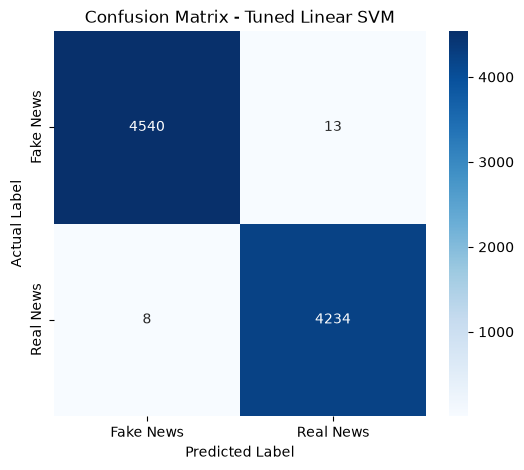

In [130]:
# Visualizing the confusion matrix

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Tuned Linear SVM")

plt.show()

In [131]:
# Creating an error analysis DataFrame

error_analysis = df.loc[X_test.index].copy()

error_analysis["actual_label"] = y_test
error_analysis["predicted_label"] = pd.Series(
    y_pred_best_svm, index=X_test.index
)

error_analysis = error_analysis[
    error_analysis["actual_label"] != error_analysis["predicted_label"]
]

print("Number of misclassified articles:", len(error_analysis))

display(
    error_analysis[
        ["title", "actual_label", "predicted_label", "text"]
    ]
)

Number of misclassified articles: 21


,title,actual_label,predicted_label,text
31637,White House budget slashes 'countering violent...,1,0,WASHINGTON (Reuters) - The budget proposal unv...
21381,HOW OBAMA’S BROKEN U.S. Deportation Process an...,0,1,U.S. Immigration and Customs Enforcement said ...
6703,BREAKING: LIBERAL HEADS WILL EXPLODE When They...,0,1,"Trump s choice of pro-oil, pro-fracking, anti-..."
39726,PRO-ILLEGAL ADVOCATE JORGE RAMOS: “Illegals ar...,0,1,THE TRUTH IS MEXICO DEPENDS ON THE BILLIONS SE...
7332,KELLOGG’S PULLS ADVERTISING From Breitbart New...,0,1,Kellogg Co. is pulling its ads from the websit...
13490,Sterling quarterback crop lead way into the pl...,1,0,(Reuters) - An evergreen crop of elite quarter...
36952,"Before the White House, Kennedy was a high-sch...",1,0,BOSTON (Reuters) - Years before he captained t...
3747,"POPE MEETS WITH ANGRY, JEWISH, PR0 LATE-TERM A...",0,1,As a Catholic I m offended by this Pope s poli...
28902,Highlights of Reuters interview with Trump,1,0,WASHINGTON (Reuters) - Here are highlights of ...
38079,BREAKING: OBAMA JUST TURNED INTERNET Over To I...,0,1,Has Obama sacrificed the freedom of speech we ...


In [132]:
# Making the errors easier to interpret 

error_analysis["actual_class"] = error_analysis["actual_label"].map({
    0: "Fake News",
    1: "Real News"
})

error_analysis["predicted_class"] = error_analysis["predicted_label"].map({
    0: "Fake News",
    1: "Real News"
})

display(
    error_analysis[
        ["title", "actual_class", "predicted_class"]
    ]
)

,title,actual_class,predicted_class
31637,White House budget slashes 'countering violent...,Real News,Fake News
21381,HOW OBAMA’S BROKEN U.S. Deportation Process an...,Fake News,Real News
6703,BREAKING: LIBERAL HEADS WILL EXPLODE When They...,Fake News,Real News
39726,PRO-ILLEGAL ADVOCATE JORGE RAMOS: “Illegals ar...,Fake News,Real News
7332,KELLOGG’S PULLS ADVERTISING From Breitbart New...,Fake News,Real News
13490,Sterling quarterback crop lead way into the pl...,Real News,Fake News
36952,"Before the White House, Kennedy was a high-sch...",Real News,Fake News
3747,"POPE MEETS WITH ANGRY, JEWISH, PR0 LATE-TERM A...",Fake News,Real News
28902,Highlights of Reuters interview with Trump,Real News,Fake News
38079,BREAKING: OBAMA JUST TURNED INTERNET Over To I...,Fake News,Real News


In [133]:
# Finding repeated titles

duplicate_titles = df[
    df["title"].duplicated(keep=False)
].sort_values("title")

print("Rows with repeated titles:", len(duplicate_titles))

display(
    duplicate_titles[
        ["title", "label"]
    ].head(30)
)

Rows with repeated titles: 10993


,title,label
24072,McConnell Says He’ll Obstruct ANY Effort To H...,0
25367,McConnell Says He’ll Obstruct ANY Effort To H...,0
7165,#AnyoneButHillary: NEW POLL Shows Bernie Suppo...,0
10403,#AnyoneButHillary: NEW POLL Shows Bernie Suppo...,0
9756,#Austin: Fights Break Out Between Police and S...,0
10477,#Austin: Fights Break Out Between Police and S...,0
981,#Berkeley CRAZY! RIOTERS CHASE And Beat People...,0
3520,#Berkeley CRAZY! RIOTERS CHASE And Beat People...,0
22328,#Berkeley IRONY ALERT! ANARCHISTS LOOT STARBUC...,0
31800,#Berkeley IRONY ALERT! ANARCHISTS LOOT STARBUC...,0


In [134]:
# Counting repeated titles

print("Unique repeated titles:", duplicate_titles["title"].nunique())

print("Total rows with repeated titles:", len(duplicate_titles))

Unique repeated titles: 5248
Total rows with repeated titles: 10993


#### Checking title overlap between training and test sets

In [135]:
# Finding titles shared between training and test data

train_titles = set(X_train.index.map(df.loc[X_train.index, "title"]))
test_titles = set(X_test.index.map(df.loc[X_test.index, "title"]))

common_titles = train_titles.intersection(test_titles)

print("Unique train titles:", len(train_titles))
print("Unique test titles:", len(test_titles))
print("Titles appearing in both sets:", len(common_titles))

Unique train titles: 31487
Unique test titles: 8526
Titles appearing in both sets: 1785


In [136]:
# Inspecting shared titles

overlapping_titles = df[
    df["title"].isin(common_titles)
].sort_values("title")

display(
    overlapping_titles[
        ["title", "label"]
    ].head(50)
)

,title,label
7165,#AnyoneButHillary: NEW POLL Shows Bernie Suppo...,0
10403,#AnyoneButHillary: NEW POLL Shows Bernie Suppo...,0
981,#Berkeley CRAZY! RIOTERS CHASE And Beat People...,0
3520,#Berkeley CRAZY! RIOTERS CHASE And Beat People...,0
22328,#Berkeley IRONY ALERT! ANARCHISTS LOOT STARBUC...,0
31800,#Berkeley IRONY ALERT! ANARCHISTS LOOT STARBUC...,0
9234,#BlackLivesMatter Supporters Say No Connection...,0
28434,#BlackLivesMatter Supporters Say No Connection...,0
7167,#CNNBlackmail Trending as Network Blackmails T...,0
24782,#CNNBlackmail Trending as Network Blackmails T...,0


In [137]:
# Calculating the overlap proportion

overlap_percentage = (
    len(common_titles) / df["title"].nunique()
) * 100

print(f"Title overlap percentage: {overlap_percentage:.2f}%")

Title overlap percentage: 4.67%


#### Calculating the actual test-set overlap rate

In [138]:
# Calculating test articles with previously seen titles

train_titles = df.loc[X_train.index, "title"].dropna().str.strip()
test_titles = df.loc[X_test.index, "title"].dropna().str.strip()

train_title_set = set(train_titles)

test_seen_mask = test_titles.isin(train_title_set)

print("Test articles:", len(test_titles))
print("Test articles with titles seen in training:", test_seen_mask.sum())

print(
    "Test-set title overlap rate:",
    f"{test_seen_mask.mean() * 100:.2f}%"
)

Test articles: 8795
Test articles with titles seen in training: 1836
Test-set title overlap rate: 20.88%


In [139]:
# Checking whether repeated titles have conflicting labels

title_label_counts = df.groupby("title")["label"].nunique()

conflicting_titles = title_label_counts[title_label_counts > 1]

print("Titles with conflicting labels:", len(conflicting_titles))

Titles with conflicting labels: 0


In [140]:
# Inspecting conflicting titles

conflicting_title_data = df[
    df["title"].isin(conflicting_titles.index)
].sort_values("title")

display(
    conflicting_title_data[
        ["title", "label"]
    ].head(50)
)

,title,label


#### Creating a Group-based train/test split

In [141]:
from sklearn.model_selection import GroupShuffleSplit

In [142]:
# Creating groups based on  titles

groups = df["title"].str.strip()

In [143]:
# Creating a group-based 80/20 split

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

group_train_idx, group_test_idx = next(
    gss.split(df["clean_text"], df["label"], groups=groups)
)

X_group_train = df["clean_text"].iloc[group_train_idx]
X_group_test = df["clean_text"].iloc[group_test_idx]

y_group_train = df["label"].iloc[group_train_idx]
y_group_test = df["label"].iloc[group_test_idx]

In [144]:
# Verifying the split

print("Training samples:", len(X_group_train))
print("Testing samples:", len(X_group_test))

print("\nTraining distribution:")
print(y_group_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_group_test.value_counts(normalize=True))

Training samples: 35192
Testing samples: 8781

Training distribution:
label
0    0.516112
1    0.483888
Name: proportion, dtype: float64

Testing distribution:
label
0    0.523858
1    0.476142
Name: proportion, dtype: float64


In [145]:
# Verifying title leakage is eliminated

group_train_titles = set(
    df["title"].iloc[group_train_idx].str.strip()
)

group_test_titles = set(
    df["title"].iloc[group_test_idx].str.strip()
)

title_overlap = group_train_titles.intersection(group_test_titles)

print("Shared titles:", len(title_overlap))

Shared titles: 0


In [146]:
# Successfully eliminated title overlap between the training and testing sets

#### Evaluating Linear SVM on unseen titles

In [147]:
# Building the pipeline

group_svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

In [148]:
# Training the model 

group_svm_pipeline.fit(X_group_train, y_group_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_df max_df: float or int, default=1.0When building the vocabulary ignore terms that have a documentfrequency strictly higher than the given threshold (corpus-specificstop words).If float in range [0.0, 1.0], the parameter represents a proportion ofdocuments, integer absolute counts.This parameter is ignored if vocabulary is not None.",0.95
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",20000
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True


In [149]:
# Making predictions

y_group_pred = group_svm_pipeline.predict(X_group_test)

In [150]:
# Evaluating the model 

print("Accuracy:", accuracy_score(y_group_test, y_group_pred))
print("Precision:", precision_score(y_group_test, y_group_pred))
print("Recall:", recall_score(y_group_test, y_group_pred))
print("F1 Score:", f1_score(y_group_test, y_group_pred))


Accuracy: 0.9945336522036214
Precision: 0.9916726147989531
Recall: 0.9968906960057402
F1 Score: 0.9942748091603053


In [151]:
# Classification report

print(classification_report(
    y_group_test,
    y_group_pred,
    target_names=["Fake News", "Real News"]
))

              precision    recall  f1-score   support

   Fake News       1.00      0.99      0.99      4600
   Real News       0.99      1.00      0.99      4181

    accuracy                           0.99      8781
   macro avg       0.99      0.99      0.99      8781
weighted avg       0.99      0.99      0.99      8781



In [152]:
# Linear SVM achieved 99.45% accuracy even after eliminating shared titles between training and testing

#### Confusion Matrix for the group-based evaluation

In [153]:
# Confusion matrix

group_cm = confusion_matrix(
    y_group_test,
    y_group_pred
)

print(group_cm)

[[4565   35]
 [  13 4168]]


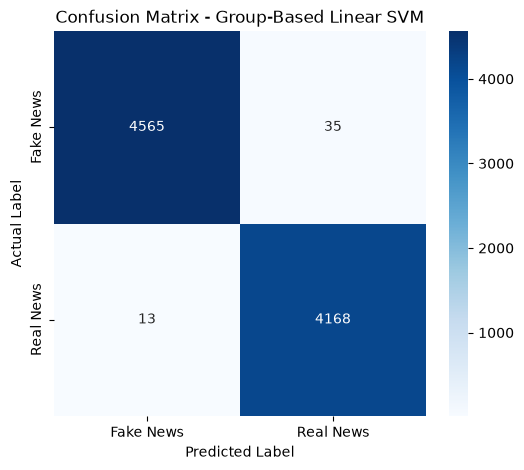

In [154]:
# Visualizing it

plt.figure(figsize=(6, 5))

sns.heatmap(
    group_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Group-Based Linear SVM")

plt.show()

In [155]:
# Extracting group-based errors

group_error_analysis = df.iloc[group_test_idx].copy()

group_error_analysis["actual_label"] = y_group_test.values
group_error_analysis["predicted_label"] = y_group_pred

group_error_analysis = group_error_analysis[
    group_error_analysis["actual_label"] !=
    group_error_analysis["predicted_label"]
]

print("Misclassified articles:", len(group_error_analysis))

display(
    group_error_analysis[
        ["title", "actual_label", "predicted_label", "text"]
    ]
)

Misclassified articles: 48


,title,actual_label,predicted_label,text
3427,ROBERT DENIRO Wanted “To Punch Trump In The Fa...,0,1,Robert De Niro gave anti-Donald Trump proteste...
3747,"POPE MEETS WITH ANGRY, JEWISH, PR0 LATE-TERM A...",0,1,As a Catholic I m offended by this Pope s poli...
4060,"From life as thugs to baking, El Salvador's ex...",1,0,SAN SALVADOR (Reuters) - Gang life in the poor...
4964,Highlights from Reuters' exclusive interview w...,1,0,(Reuters) - Below are the highlights from Reut...
5117,AS TRUMP’S POPULARITY SOARS ABROAD…Village In ...,0,1,President Donald Trump welcomed India s Prime ...
6628,ROBERT DENIRO Wanted “To Punch Trump In The Fa...,0,1,Robert De Niro gave anti-Donald Trump proteste...
7125,Reuters News Agency Declares War On Trump In ...,0,1,Donald Trump s treatment of journalists is so ...
7176,BREAKING: WHY DID MASSACHUSETTS OFFICIALS WAIT...,0,1,Where was the media coverage when this black t...
7757,Saudi Man Threatens Backlash Over New Law Allo...,0,1,Women in Saudi Arabia were just given the righ...
7931,Reaction to death of U.S. Justice Scalia,1,0,(Reuters) - Conservative U.S. Supreme Court Ju...


In [156]:
# Examining all 48 misclassified articles

group_error_analysis[
    ["title", "actual_label", "predicted_label", "text"]
].head(10)

,title,actual_label,predicted_label,text
3427,ROBERT DENIRO Wanted “To Punch Trump In The Fa...,0,1,Robert De Niro gave anti-Donald Trump proteste...
3747,"POPE MEETS WITH ANGRY, JEWISH, PR0 LATE-TERM A...",0,1,As a Catholic I m offended by this Pope s poli...
4060,"From life as thugs to baking, El Salvador's ex...",1,0,SAN SALVADOR (Reuters) - Gang life in the poor...
4964,Highlights from Reuters' exclusive interview w...,1,0,(Reuters) - Below are the highlights from Reut...
5117,AS TRUMP’S POPULARITY SOARS ABROAD…Village In ...,0,1,President Donald Trump welcomed India s Prime ...
6628,ROBERT DENIRO Wanted “To Punch Trump In The Fa...,0,1,Robert De Niro gave anti-Donald Trump proteste...
7125,Reuters News Agency Declares War On Trump In ...,0,1,Donald Trump s treatment of journalists is so ...
7176,BREAKING: WHY DID MASSACHUSETTS OFFICIALS WAIT...,0,1,Where was the media coverage when this black t...
7757,Saudi Man Threatens Backlash Over New Law Allo...,0,1,Women in Saudi Arabia were just given the righ...
7931,Reaction to death of U.S. Justice Scalia,1,0,(Reuters) - Conservative U.S. Supreme Court Ju...


####  Investigating source-related shortcuts

In [157]:
# Checking Reuters markers in the dataset

df["contains_reuters"] = df["text"].str.contains(
    r"\bReuters\b",
    case=False,
    regex=True,
    na=False
)

pd.crosstab(
    df["label"],
    df["contains_reuters"],
    normalize="index"
) * 100

contains_reuters,False,True
label,,
0,98.646927,1.353073
1,0.179161,99.820839


In [158]:
# Reuters-only baseline

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

reuters_baseline_pred = df["contains_reuters"].astype(int)

print("Accuracy:", accuracy_score(df["label"], reuters_baseline_pred))

print("\nClassification Report:")
print(
    classification_report(
        df["label"],
        reuters_baseline_pred,
        target_names=["Fake News", "Real News"]
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(df["label"], reuters_baseline_pred))

Accuracy: 0.9921315352602733

Classification Report:
              precision    recall  f1-score   support

   Fake News       1.00      0.99      0.99     22763
   Real News       0.99      1.00      0.99     21210

    accuracy                           0.99     43973
   macro avg       0.99      0.99      0.99     43973
weighted avg       0.99      0.99      0.99     43973


Confusion Matrix:
[[22455   308]
 [   38 21172]]


In [159]:
# Fair comparison on the group-based test set

group_test_df = df.iloc[group_test_idx].copy()

reuters_group_pred = group_test_df["contains_reuters"].astype(int)
reuters_group_actual = y_group_test

print("Reuters Baseline Accuracy:",
      accuracy_score(reuters_group_actual, reuters_group_pred))

print("\nClassification Report:")
print(
    classification_report(
        reuters_group_actual,
        reuters_group_pred,
        target_names=["Fake News", "Real News"]
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        reuters_group_actual,
        reuters_group_pred
    )
)

Reuters Baseline Accuracy: 0.9925976540257374

Classification Report:
              precision    recall  f1-score   support

   Fake News       1.00      0.99      0.99      4600
   Real News       0.99      1.00      0.99      4181

    accuracy                           0.99      8781
   macro avg       0.99      0.99      0.99      8781
weighted avg       0.99      0.99      0.99      8781


Confusion Matrix:
[[4542   58]
 [   7 4174]]


#### Shortcut removal experiment: Remove Reuters from text

In [160]:
# Removing Reuters tokens

df["clean_text_no_reuters"] = df["clean_text"].str.replace(
    r"\breuter(?:s)?\b",
    "",
    regex=True
)

df["clean_text_no_reuters"] = df["clean_text_no_reuters"].str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()

In [161]:
# Training a new grouped SVM without Reuters

group_svm_no_reuters = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

X_no_reuters_train = df["clean_text_no_reuters"].iloc[group_train_idx]
X_no_reuters_test = df["clean_text_no_reuters"].iloc[group_test_idx]

group_svm_no_reuters.fit(
    X_no_reuters_train,
    y_group_train
)

y_no_reuters_pred = group_svm_no_reuters.predict(
    X_no_reuters_test
)

In [162]:
# Evaluating the model 

print("Accuracy:",
      accuracy_score(y_group_test, y_no_reuters_pred))

print("Precision:",
      precision_score(y_group_test, y_no_reuters_pred))

print("Recall:",
      recall_score(y_group_test, y_no_reuters_pred))

print("F1 Score:",
      f1_score(y_group_test, y_no_reuters_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_group_test,
        y_no_reuters_pred,
        target_names=["Fake News", "Real News"]
    )
)

Accuracy: 0.9872451884751168
Precision: 0.9808555896951076
Recall: 0.9925855058598422
F1 Score: 0.9866856871136471

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.99      4600
   Real News       0.98      0.99      0.99      4181

    accuracy                           0.99      8781
   macro avg       0.99      0.99      0.99      8781
weighted avg       0.99      0.99      0.99      8781



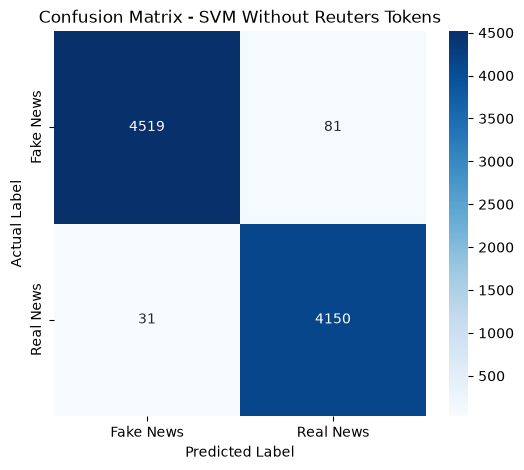

In [163]:
# Confusion matrix for Reuters-Removed SVM

no_reuters_cm = confusion_matrix(
    y_group_test,
    y_no_reuters_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    no_reuters_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - SVM Without Reuters Tokens")

plt.show()

In [164]:
# Extract misclassified articles

no_reuters_error_analysis = df.iloc[group_test_idx].copy()

no_reuters_error_analysis["actual_label"] = y_group_test.values
no_reuters_error_analysis["predicted_label"] = y_no_reuters_pred

no_reuters_error_analysis = no_reuters_error_analysis[
    no_reuters_error_analysis["actual_label"] !=
    no_reuters_error_analysis["predicted_label"]
]

print("Misclassified articles:", len(no_reuters_error_analysis))

display(
    no_reuters_error_analysis[
        ["title", "actual_label", "predicted_label", "text"]
    ].head(15)
)


Misclassified articles: 112


,title,actual_label,predicted_label,text
896,PALESTINIANS STEPPING UP STABBINGS: Dramatic V...,0,1,***Warning*** Graphic photo and videoThank goo...
2918,Gerald Celente: Top 10 Trends for 2017,0,1,"What can we expect in 2017? Inflated markets, ..."
3058,TWO ILLEGAL ALIENS TO BECOME FIRST APPOINTED C...,0,1,Is there really any point to go through the wo...
3427,ROBERT DENIRO Wanted “To Punch Trump In The Fa...,0,1,Robert De Niro gave anti-Donald Trump proteste...
3747,"POPE MEETS WITH ANGRY, JEWISH, PR0 LATE-TERM A...",0,1,As a Catholic I m offended by this Pope s poli...
4060,"From life as thugs to baking, El Salvador's ex...",1,0,SAN SALVADOR (Reuters) - Gang life in the poor...
4222,CNN HOST Doesn’t Recognize Star Spangled Banne...,0,1,When reporting on President Donald Trump s mee...
4413,BREAKING: DEMS TRY TO SCAPEGOAT: Release Colin...,0,1,The top Democrat on the House committee invest...
4514,BREAKING: US SUPREME COURT RULES King Obama Ov...,0,1,Don t let the door hit ya B..b..but who will b...
4964,Highlights from Reuters' exclusive interview w...,1,0,(Reuters) - Below are the highlights from Reut...


In [165]:
# Inspecting the 112 errors

display(
    no_reuters_error_analysis[
        ["title", "actual_label", "predicted_label", "text"]
    ].head(15)
)

,title,actual_label,predicted_label,text
896,PALESTINIANS STEPPING UP STABBINGS: Dramatic V...,0,1,***Warning*** Graphic photo and videoThank goo...
2918,Gerald Celente: Top 10 Trends for 2017,0,1,"What can we expect in 2017? Inflated markets, ..."
3058,TWO ILLEGAL ALIENS TO BECOME FIRST APPOINTED C...,0,1,Is there really any point to go through the wo...
3427,ROBERT DENIRO Wanted “To Punch Trump In The Fa...,0,1,Robert De Niro gave anti-Donald Trump proteste...
3747,"POPE MEETS WITH ANGRY, JEWISH, PR0 LATE-TERM A...",0,1,As a Catholic I m offended by this Pope s poli...
4060,"From life as thugs to baking, El Salvador's ex...",1,0,SAN SALVADOR (Reuters) - Gang life in the poor...
4222,CNN HOST Doesn’t Recognize Star Spangled Banne...,0,1,When reporting on President Donald Trump s mee...
4413,BREAKING: DEMS TRY TO SCAPEGOAT: Release Colin...,0,1,The top Democrat on the House committee invest...
4514,BREAKING: US SUPREME COURT RULES King Obama Ov...,0,1,Don t let the door hit ya B..b..but who will b...
4964,Highlights from Reuters' exclusive interview w...,1,0,(Reuters) - Below are the highlights from Reut...


#### Title-only vs. Article-body-only experiment

In [166]:
# Will now test whether the model relies more on headlines or on the article body.

In [167]:
# Preprocessing titles

df["clean_title"] = df["title"].apply(preprocess_text)

In [168]:
# Creating the title-only model

title_svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

X_title_train = df["clean_title"].iloc[group_train_idx]
X_title_test = df["clean_title"].iloc[group_test_idx]

title_svm_pipeline.fit(
    X_title_train,
    y_group_train
)

y_title_pred = title_svm_pipeline.predict(X_title_test)

In [169]:
# Evaluating the title-only model

print("Title-only Accuracy:",
      accuracy_score(y_group_test, y_title_pred))

print("Title-only Precision:",
      precision_score(y_group_test, y_title_pred))

print("Title-only Recall:",
      recall_score(y_group_test, y_title_pred))

print("Title-only F1:",
      f1_score(y_group_test, y_title_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_group_test,
        y_title_pred,
        target_names=["Fake News", "Real News"]
    )
)

Title-only Accuracy: 0.9394146452568045
Title-only Precision: 0.9224357490159759
Title-only Recall: 0.9528820856254484
Title-only F1: 0.9374117647058824

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.96      0.93      0.94      4600
   Real News       0.92      0.95      0.94      4181

    accuracy                           0.94      8781
   macro avg       0.94      0.94      0.94      8781
weighted avg       0.94      0.94      0.94      8781



In [170]:
# Creating the body-only model

body_svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

X_body_train = df["clean_text_no_reuters"].iloc[group_train_idx]
X_body_test = df["clean_text_no_reuters"].iloc[group_test_idx]

body_svm_pipeline.fit(
    X_body_train,
    y_group_train
)

y_body_pred = body_svm_pipeline.predict(X_body_test)

In [171]:
# Evaluating the body-only model

print("Body-only Accuracy:",
      accuracy_score(y_group_test, y_body_pred))

print("Body-only Precision:",
      precision_score(y_group_test, y_body_pred))

print("Body-only Recall:",
      recall_score(y_group_test, y_body_pred))

print("Body-only F1:",
      f1_score(y_group_test, y_body_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_group_test,
        y_body_pred,
        target_names=["Fake News", "Real News"]
    )
)

Body-only Accuracy: 0.9872451884751168
Body-only Precision: 0.9808555896951076
Body-only Recall: 0.9925855058598422
Body-only F1: 0.9866856871136471

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.99      4600
   Real News       0.98      0.99      0.99      4181

    accuracy                           0.99      8781
   macro avg       0.99      0.99      0.99      8781
weighted avg       0.99      0.99      0.99      8781



#### Combining Title + Body model

In [172]:
df["combined_text"] = (
    df["clean_title"] + " " + df["clean_text_no_reuters"]
)

In [173]:
# Training the combined model

combined_svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

X_combined_train = df["combined_text"].iloc[group_train_idx]
X_combined_test = df["combined_text"].iloc[group_test_idx]

combined_svm_pipeline.fit(
    X_combined_train,
    y_group_train
)

y_combined_pred = combined_svm_pipeline.predict(
    X_combined_test
)

In [174]:
# Evaluating the combined model

print("Combined Accuracy:",
      accuracy_score(y_group_test, y_combined_pred))

print("Combined Precision:",
      precision_score(y_group_test, y_combined_pred))

print("Combined Recall:",
      recall_score(y_group_test, y_combined_pred))

print("Combined F1:",
      f1_score(y_group_test, y_combined_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_group_test,
        y_combined_pred,
        target_names=["Fake News", "Real News"]
    )
)

Combined Accuracy: 0.9882701286869378
Combined Precision: 0.9824893516327496
Combined Recall: 0.9930638603204975
Combined F1: 0.987748304983942

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.99      4600
   Real News       0.98      0.99      0.99      4181

    accuracy                           0.99      8781
   macro avg       0.99      0.99      0.99      8781
weighted avg       0.99      0.99      0.99      8781



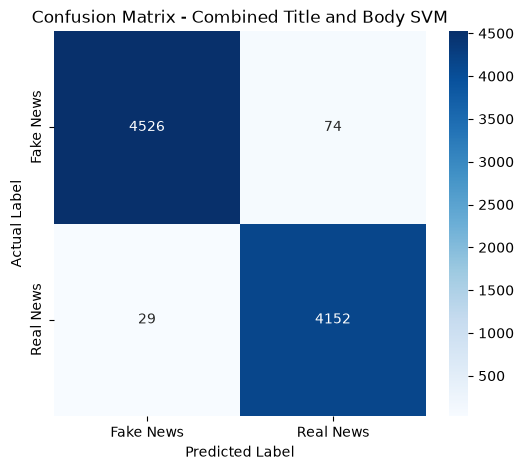

In [175]:
# Confusion matrix

combined_cm = confusion_matrix(
    y_group_test,
    y_combined_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    combined_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Combined Title and Body SVM")

plt.show()

In [176]:
# Building a single experiment table to track all the experiments

# Experiment comparison table
experiment_results = pd.DataFrame([
    {
        "Model": "Reuters-only baseline",
        "Accuracy": 0.9925976540257374,
        "Precision": np.nan,
        "Recall": np.nan,
        "F1": np.nan
    },
    {
        "Model": "Original Group SVM",
        "Accuracy": 0.9945336522036214,
        "Precision": 0.9916726147989532,
        "Recall": 0.9968906960057402,
        "F1": 0.9942748091603053
    },
    {
        "Model": "SVM without Reuters",
        "Accuracy": 0.9872451884751168,
        "Precision": 0.9808555896951076,
        "Recall": 0.9925855058598422,
        "F1": 0.9866856871136471
    },
    {
        "Model": "Title-only SVM",
        "Accuracy": 0.9394146452568045,
        "Precision": 0.9224357490159759,
        "Recall": 0.9528820856254484,
        "F1": 0.9374117647058824
    },
    {
        "Model": "Body-only SVM",
        "Accuracy": 0.9872451884751168,
        "Precision": 0.9808555896951076,
        "Recall": 0.9925855058598422,
        "F1": 0.9866856871136471
    },
    {
        "Model": "Combined Title + Body SVM",
        "Accuracy": 0.9882701286869378,
        "Precision": 0.9824893516327496,
        "Recall": 0.9930638603204975,
        "F1": 0.987748304983942
    }
])

experiment_results.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)


,Model,Accuracy,Precision,Recall,F1
0,Original Group SVM,0.994534,0.991673,0.996891,0.994275
1,Combined Title + Body SVM,0.988270,0.982489,0.993064,0.987748
2,SVM without Reuters,0.987245,0.980856,0.992586,0.986686
3,Body-only SVM,0.987245,0.980856,0.992586,0.986686
4,Title-only SVM,0.939415,0.922436,0.952882,0.937412
5,Reuters-only baseline,0.992598,NaN,NaN,NaN


In [177]:
# Reuters baseline evaluation

print("Accuracy:",
      accuracy_score(reuters_group_actual, reuters_group_pred))

print("Precision:",
      precision_score(reuters_group_actual, reuters_group_pred))

print("Recall:",
      recall_score(reuters_group_actual, reuters_group_pred))

print("F1 Score:",
      f1_score(reuters_group_actual, reuters_group_pred))

Accuracy: 0.9925976540257374
Precision: 0.9862948960302458
Recall: 0.9983257593877063
F1 Score: 0.9922738618804231


In [178]:
# Updating the complete comparison table

experiment_results.loc[
    experiment_results["Model"] == "Reuters-only baseline",
    ["Accuracy", "Precision", "Recall", "F1"]
] = [
    accuracy_score(reuters_group_actual, reuters_group_pred),
    precision_score(reuters_group_actual, reuters_group_pred),
    recall_score(reuters_group_actual, reuters_group_pred),
    f1_score(reuters_group_actual, reuters_group_pred)
]

experiment_results.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)


,Model,Accuracy,Precision,Recall,F1
0,Original Group SVM,0.994534,0.991673,0.996891,0.994275
1,Reuters-only baseline,0.992598,0.986295,0.998326,0.992274
2,Combined Title + Body SVM,0.988270,0.982489,0.993064,0.987748
3,SVM without Reuters,0.987245,0.980856,0.992586,0.986686
4,Body-only SVM,0.987245,0.980856,0.992586,0.986686
5,Title-only SVM,0.939415,0.922436,0.952882,0.937412


#### Temporal robustness audit

Model may perform extremely well on news from 2016–2017 but struggle with news published in later years. Next experiment will investigate the dates in the dataset and prepare a chronological evaluation.

In [179]:
# Inspecting date information

print("Date dtype:", df["date"].dtype)

print("\nSample dates:")
display(df["date"].sample(20, random_state=42))

print("\nMissing dates:")
print(df["date"].isna().sum())

print("\nUnique dates:")
print(df["date"].nunique())

Date dtype: str

Sample dates:


27705           Jun 10, 2015
42686      November 27, 2017
31907         March 31, 2016
33430     December 17, 2017 
31545           Jul 30, 2015
23231           Jan 30, 2016
27575     December 20, 2017 
116       December 14, 2017 
41679     November 20, 2016 
20205           Dec 27, 2016
2830         March 10, 2017 
21077           Oct 17, 2017
41995           Jun 23, 2015
12187     September 7, 2016 
21190    September 25, 2017 
36474           Aug 11, 2016
18142         June 27, 2017 
26914          April 7, 2017
10111      February 13, 2016
4028            Jun 26, 2016
Name: date, dtype: str


Missing dates:
0

Unique dates:
2391


In [180]:
# Converting date strings into datetime

df["parsed_date"] = pd.to_datetime(
    df["date"],
    format="mixed",
    errors="coerce"
)

print("Date dtype:", df["parsed_date"].dtype)

print("Invalid dates:", df["parsed_date"].isna().sum())

print("\nEarliest date:")
print(df["parsed_date"].min())

print("\nLatest date:")
print(df["parsed_date"].max())

Date dtype: datetime64[us]
Invalid dates: 1

Earliest date:
2015-03-31 00:00:00

Latest date:
2018-02-19 00:00:00


In [181]:
# Inspecting the invalid date

display(
    df[df["parsed_date"].isna()][
        ["title", "date", "label"]
    ]
)

,title,date,label
18951,Homepage,MSNBC HOST Rudely Assumes Steel Worker Would N...,0


In [182]:
# Creating the clean temporal dataset

temporal_df = df[df["parsed_date"].notna()].copy()

temporal_df = temporal_df.sort_values(
    "parsed_date"
).reset_index(drop=True)

print("Temporal dataset shape:", temporal_df.shape)
print("Earliest date:", temporal_df["parsed_date"].min())
print("Latest date:", temporal_df["parsed_date"].max())
print("Invalid dates remaining:", temporal_df["parsed_date"].isna().sum())

Temporal dataset shape: (43972, 11)
Earliest date: 2015-03-31 00:00:00
Latest date: 2018-02-19 00:00:00
Invalid dates remaining: 0


In [183]:
# Identifying the chronological cutoff

cutoff_date = temporal_df["parsed_date"].quantile(0.80)

print("Temporal cutoff date:", cutoff_date)

Temporal cutoff date: 2017-10-13 00:00:00


In [184]:
# Creating temporal train and test sets

temporal_train = temporal_df[
    temporal_df["parsed_date"] < cutoff_date
].copy()

temporal_test = temporal_df[
    temporal_df["parsed_date"] >= cutoff_date
].copy()

print("Training samples:", len(temporal_train))
print("Testing samples:", len(temporal_test))

print("\nTraining date range:")
print(temporal_train["parsed_date"].min(), "to",
      temporal_train["parsed_date"].max())

print("\nTesting date range:")
print(temporal_test["parsed_date"
].min(), "to",
      temporal_test["parsed_date"].max())

Training samples: 35124
Testing samples: 8848

Training date range:
2015-03-31 00:00:00 to 2017-10-12 00:00:00

Testing date range:
2017-10-13 00:00:00 to 2018-02-19 00:00:00


In [185]:
# Checking duplicate title overlap

temporal_train_titles = set(
    temporal_train["title"].str.strip()
)

temporal_test_titles = set(
    temporal_test["title"].str.strip()
)

shared_temporal_titles = (
    temporal_train_titles & temporal_test_titles
)

print("Shared titles:", len(shared_temporal_titles))

Shared titles: 1


#### Removing title overlap from temporal training

In [186]:
# Identifying the overlapping title

display(
    temporal_train[
        temporal_train["title"].str.strip().isin(shared_temporal_titles)
    ][["title", "parsed_date", "label"]]
)

,title,parsed_date,label
35068,White House says it can't lawfully pay Obamaca...,2017-10-12,1


In [187]:
# Removing overlapping titles from training

temporal_train_clean = temporal_train[
    ~temporal_train["title"].str.strip().isin(shared_temporal_titles)
].copy()

print("Training samples before:", len(temporal_train))
print("Training samples after:", len(temporal_train_clean))
print("Testing samples:", len(temporal_test))

remaining_overlap = (
    set(temporal_train_clean["title"].str.strip())
    & set(temporal_test["title"].str.strip())
)

print("Remaining shared titles:", len(remaining_overlap))

Training samples before: 35124
Training samples after: 35123
Testing samples: 8848
Remaining shared titles: 0


#### Training Linear SVM on temporal data

In [188]:
# Building the temporal SVM pipeline

temporal_svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

In [189]:
# Training the model

temporal_svm_pipeline.fit(
    temporal_train_clean["clean_text"],
    temporal_train_clean["label"]
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_df max_df: float or int, default=1.0When building the vocabulary ignore terms that have a documentfrequency strictly higher than the given threshold (corpus-specificstop words).If float in range [0.0, 1.0], the parameter represents a proportion ofdocuments, integer absolute counts.This parameter is ignored if vocabulary is not None.",0.95
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",20000
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True


In [190]:
# Predictng future news

y_temporal_pred = temporal_svm_pipeline.predict(
    temporal_test["clean_text"]
)

y_temporal_true = temporal_test["label"]

In [191]:
# Evaluating temporal performance

temporal_accuracy = accuracy_score(
    y_temporal_true, y_temporal_pred
)

temporal_precision = precision_score(
    y_temporal_true, y_temporal_pred
)

temporal_recall = recall_score(
    y_temporal_true, y_temporal_pred
)

temporal_f1 = f1_score(
    y_temporal_true, y_temporal_pred
)

print("Temporal Accuracy:", temporal_accuracy)
print("Temporal Precision:", temporal_precision)
print("Temporal Recall:", temporal_recall)
print("Temporal F1 Score:", temporal_f1)

print("\nClassification Report:")
print(classification_report(
    y_temporal_true,
    y_temporal_pred,
    target_names=["Fake News", "Real News"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_temporal_true, y_temporal_pred))

Temporal Accuracy: 0.9963833634719711
Temporal Precision: 0.9983907737696125
Temporal Recall: 0.9973208305425318
Temporal F1 Score: 0.9978555153464683

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.99      0.99      0.99      1383
   Real News       1.00      1.00      1.00      7465

    accuracy                           1.00      8848
   macro avg       0.99      0.99      0.99      8848
weighted avg       1.00      1.00      1.00      8848


Confusion Matrix:
[[1371   12]
 [  20 7445]]


#### Investigating the Reuters shortcut in the temporal test

In [192]:
# Reuters distribution across temporal datasets

print("Temporal Training Reuters distribution:")
display(
    temporal_train_clean["text"].str.contains(
        r"\bReuters\b", case=False, regex=True, na=False
    ).value_counts(normalize=True)
)

print("\nTemporal Testing Reuters distribution:")
display(
    temporal_test["text"].str.contains(
        r"\bReuters\b", case=False, regex=True, na=False
    ).value_counts(normalize=True)
)

Temporal Training Reuters distribution:


text
False    0.60123
True     0.39877
Name: proportion, dtype: float64


Temporal Testing Reuters distribution:


text
True     0.844598
False    0.155402
Name: proportion, dtype: float64

In [193]:
# Reuters distribution by class in temporal test

temporal_test_reuters = temporal_test.copy()

temporal_test_reuters["contains_reuters"] = (
    temporal_test_reuters["text"].str.contains(
        r"\bReuters\b",
        case=False,
        regex=True,
        na=False
    )
)

display(
    pd.crosstab(
        temporal_test_reuters["label"],
        temporal_test_reuters["contains_reuters"],
        normalize="index"
    )
)

contains_reuters,False,True
label,,
0,0.989154,0.010846
1,0.000938,0.999062


### Temporal SVM without Reuters

In [194]:
# Building the Reuters-removed temporal pipeline

temporal_svm_no_reuters = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

In [195]:
# Training without Reuters

temporal_svm_no_reuters.fit(
    temporal_train_clean["clean_text_no_reuters"],
    temporal_train_clean["label"]
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_df max_df: float or int, default=1.0When building the vocabulary ignore terms that have a documentfrequency strictly higher than the given threshold (corpus-specificstop words).If float in range [0.0, 1.0], the parameter represents a proportion ofdocuments, integer absolute counts.This parameter is ignored if vocabulary is not None.",0.95
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",20000
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True


In [196]:
# Predicting temporal test data

y_temporal_no_reuters_pred = temporal_svm_no_reuters.predict(
    temporal_test["clean_text_no_reuters"]
)

y_temporal_no_reuters_true = temporal_test["label"]

In [197]:
# Evaluating the model

temporal_no_reuters_accuracy = accuracy_score(
    y_temporal_no_reuters_true,
    y_temporal_no_reuters_pred
)

temporal_no_reuters_precision = precision_score(
    y_temporal_no_reuters_true,
    y_temporal_no_reuters_pred
)

temporal_no_reuters_recall = recall_score(
    y_temporal_no_reuters_true,
    y_temporal_no_reuters_pred
)

temporal_no_reuters_f1 = f1_score(
    y_temporal_no_reuters_true,
    y_temporal_no_reuters_pred
)

print("Temporal Accuracy:", temporal_no_reuters_accuracy)
print("Temporal Precision:", temporal_no_reuters_precision)
print("Temporal Recall:", temporal_no_reuters_recall)
print("Temporal F1 Score:", temporal_no_reuters_f1)

print("\nClassification Report:")
print(classification_report(
    y_temporal_no_reuters_true,
    y_temporal_no_reuters_pred,
    target_names=["Fake News", "Real News"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_temporal_no_reuters_true,
    y_temporal_no_reuters_pred
))

Temporal Accuracy: 0.9897151898734177
Temporal Precision: 0.9963651050080775
Temporal Recall: 0.9914266577361018
Temporal F1 Score: 0.9938897468609413

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.95      0.98      0.97      1383
   Real News       1.00      0.99      0.99      7465

    accuracy                           0.99      8848
   macro avg       0.98      0.99      0.98      8848
weighted avg       0.99      0.99      0.99      8848


Confusion Matrix:
[[1356   27]
 [  64 7401]]


#### Temporal error analysis without Reuters

In [198]:
# Extract misclassified articles

temporal_errors = temporal_test.copy()

temporal_errors["predicted_label"] = y_temporal_no_reuters_pred

temporal_errors = temporal_errors[
    temporal_errors["label"] != temporal_errors["predicted_label"]
].copy()

temporal_errors["prediction_type"] = np.where(
    temporal_errors["label"] == 0,
    "Fake predicted as Real",
    "Real predicted as Fake"
)

print("Total misclassified articles:", len(temporal_errors))

display(
    temporal_errors[
        ["title", "parsed_date", "label", "predicted_label", "prediction_type"]
    ].head(20)
)

Total misclassified articles: 91


,title,parsed_date,label,predicted_label,prediction_type
35172,"Netanyahu lauds Trump's Iran turn, sees chance...",2017-10-13,1,0,Real predicted as Fake
35173,Etihad flight from Abu Dhabi makes emergency l...,2017-10-13,1,0,Real predicted as Fake
35241,"Netanyahu lauds Trump's Iran turn, sees chance...",2017-10-13,1,0,Real predicted as Fake
35446,"'Mad dog' anti-Trump leaflets, suspected float...",2017-10-16,1,0,Real predicted as Fake
35460,North Korea warns states: Don't join any U.S. ...,2017-10-16,1,0,Real predicted as Fake
35585,Opposition challenges Venezuelan socialists' v...,2017-10-16,1,0,Real predicted as Fake
35612,A 'goddess party secretary' ponders her future...,2017-10-17,1,0,Real predicted as Fake
35631,"ASPIRATIONS: Young Chinese seize the day, seiz...",2017-10-17,1,0,Real predicted as Fake
35636,A young Chinese rebel feels the pull of family...,2017-10-17,1,0,Real predicted as Fake
35639,INTERNET: Living with the Great Firewall of China,2017-10-17,1,0,Real predicted as Fake


In [199]:
# Separating the two types of mistakes

fake_predicted_real = temporal_errors[
    temporal_errors["prediction_type"] == "Fake predicted as Real"
]

real_predicted_fake = temporal_errors[
    temporal_errors["prediction_type"] == "Real predicted as Fake"
]

print("Fake predicted as Real:", len(fake_predicted_real))
print("Real predicted as Fake:", len(real_predicted_fake))

Fake predicted as Real: 27
Real predicted as Fake: 64


In [200]:
# Inspecting fake articles predicted as real

display(
    fake_predicted_real[
        ["title", "text", "parsed_date"]
    ].head(10)
)

,title,text,parsed_date
36661,BREAKING: BROTHER Of Las Vegas Massacre Suspec...,"By now, most of America has seen the crazy vid...",2017-10-25
36689,BREAKING: BROTHER Of Las Vegas Massacre Suspec...,"By now, most of America has seen the crazy vid...",2017-10-25
37062,THE U.S. IMPORTS MORE AFRICAN REFUGEES AS PLAG...,One of the fastest growing groups of refugees ...,2017-10-28
37422,JUST IN: Senior GOP Rep Announces His Retireme...,"Rep. Jeb Hensarling (R., Texas) announced Tues...",2017-10-31
38003,JUST IN: Helicopter Crashes In Saudi Arabia KI...,"Zero Hedge In a shocking development, late o...",2017-11-05
38119,LOL! MOTHER OF TWO Just Got A BIG SURPRISE Fro...,"The picture, snapped by a White House photogra...",2017-11-06
38136,LOL! MOTHER OF TWO Just Got A BIG SURPRISE Fro...,"The picture, snapped by a White House photogra...",2017-11-06
41406,JUST IN: SUPREME COURT Rules On Trump Travel Ban,Another winner for America and for President T...,2017-12-04
41414,JUST IN: SUPREME COURT Rules On Trump Travel Ban,Another winner for America and for President T...,2017-12-04
41491,HYPOCRISY: DEMOCRAT SENATOR Criticizes Preside...,You just can t make up stories like these Demo...,2017-12-05


In [201]:
# Inspecting real articles predicted as fake

display(
    real_predicted_fake[
        ["title", "text", "parsed_date"]
    ].head(10)
)

,title,text,parsed_date
35172,"Netanyahu lauds Trump's Iran turn, sees chance...",JERUSALEM (Reuters) - Israeli Prime Minister B...,2017-10-13
35173,Etihad flight from Abu Dhabi makes emergency l...,SYDNEY (Reuters) - An Etihad Airways flight tr...,2017-10-13
35241,"Netanyahu lauds Trump's Iran turn, sees chance...",JERUSALEM (Reuters) - Israeli Prime Minister B...,2017-10-13
35446,"'Mad dog' anti-Trump leaflets, suspected float...",SEOUL (Reuters) - Propaganda fliers presumed t...,2017-10-16
35460,North Korea warns states: Don't join any U.S. ...,UNITED NATIONS (Reuters) - North Korea warned ...,2017-10-16
35585,Opposition challenges Venezuelan socialists' v...,CARACAS (Reuters) - Venezuela s opposition coa...,2017-10-16
35612,A 'goddess party secretary' ponders her future...,"WUHAN, China (Reuters) - In the mid 1980s, as ...",2017-10-17
35631,"ASPIRATIONS: Young Chinese seize the day, seiz...",(Reuters) - The world is this generation s oys...,2017-10-17
35636,A young Chinese rebel feels the pull of family...,"CHENGDU, China (Reuters) - Her stepfather was ...",2017-10-17
35639,INTERNET: Living with the Great Firewall of China,(Reuters) - The Great Firewall of China th...,2017-10-17


#### Checking whether our errors include duplicate articles

In [202]:
# Analyzing duplicate titles in the errors

print("Total error rows:", len(temporal_errors))
print("Unique error titles:", temporal_errors["title"].nunique())

print("\nMost frequently misclassified titles:")

display(
    temporal_errors["title"]
    .value_counts()
    .head(15)
)

Total error rows: 91
Unique error titles: 79

Most frequently misclassified titles:


title
Netanyahu lauds Trump's Iran turn, sees chance to change nuclear deal                                                                                        2
BREAKING: BROTHER Of Las Vegas Massacre Suspect Has Been ARRESTED In California                                                                              2
LOL! MOTHER OF TWO Just Got A BIG SURPRISE From Her Employer After She Became A Hero To Democrats For FLIPPING OFF President Trump’s Motorcade               2
JUST IN: SUPREME COURT Rules On Trump Travel Ban                                                                                                             2
HYPOCRISY: DEMOCRAT SENATOR Criticizes President Trump For Moving U.S. Embassy To Jerusalem After She Voted To Move U.S. Embassy To Jerusalem                2
JUST IN: OBAMA APPOINTED JUDGE Presiding Over Michael Flynn’s Case SUDDENLY Recuses Himself…CLINTON Appointed Judge Will Sentence Flynn                      2
Palestinian Protesters Attack US Embassy

In [203]:
# Analyzing errors by prediction type and unique title

error_title_summary = (
    temporal_errors.groupby("prediction_type")
    .agg(
        error_rows=("title", "count"),
        unique_titles=("title", "nunique")
    )
)

display(error_title_summary)

,error_rows,unique_titles
prediction_type,,
Fake predicted as Real,27,16
Real predicted as Fake,64,63


#### Checking duplicate titles within temporal test

In [204]:
print("Temporal test rows:", len(temporal_test))
print("Unique titles:", temporal_test["title"].str.strip().nunique())
print("Duplicate title rows:", 
      len(temporal_test) - temporal_test["title"].str.strip().nunique())

Temporal test rows: 8848
Unique titles: 8235
Duplicate title rows: 613


In [205]:
# Creating unique-title test dataset

temporal_test_unique = temporal_test.copy()

temporal_test_unique["normalized_title"] = (
    temporal_test_unique["title"].str.strip()
)

temporal_test_unique = temporal_test_unique.drop_duplicates(
    subset="normalized_title"
).copy()

print("Original test rows:", len(temporal_test))
print("Unique-title test rows:", len(temporal_test_unique))

Original test rows: 8848
Unique-title test rows: 8235


In [206]:
# Predicting unique-title articles

y_temporal_unique_pred = temporal_svm_no_reuters.predict(
    temporal_test_unique["clean_text_no_reuters"]
)

y_temporal_unique_true = temporal_test_unique["label"]

In [207]:
# Evaluating unique-title performance

print("Unique-title Accuracy:",
      accuracy_score(y_temporal_unique_true, y_temporal_unique_pred))

print("Unique-title Precision:",
      precision_score(y_temporal_unique_true, y_temporal_unique_pred))

print("Unique-title Recall:",
      recall_score(y_temporal_unique_true, y_temporal_unique_pred))

print("Unique-title F1:",
      f1_score(y_temporal_unique_true, y_temporal_unique_pred))

print("\nClassification Report:")
print(classification_report(
    y_temporal_unique_true,
    y_temporal_unique_pred,
    target_names=["Fake News", "Real News"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_temporal_unique_true,
    y_temporal_unique_pred
))


Unique-title Accuracy: 0.9904068002428659
Unique-title Precision: 0.9977845472168374
Unique-title Recall: 0.9913330581923235
Unique-title F1: 0.9945483403491823

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.94      0.98      0.96       966
   Real News       1.00      0.99      0.99      7269

    accuracy                           0.99      8235
   macro avg       0.97      0.99      0.98      8235
weighted avg       0.99      0.99      0.99      8235


Confusion Matrix:
[[ 950   16]
 [  63 7206]]


#### Consolidating our robustness experiments

In [208]:
# Building the robustness comparison table

robustness_results = pd.DataFrame([
    {
        "Experiment": "Random Split - Original SVM",
        "Accuracy": 0.997612,
        "Precision": 0.996939,
        "Recall": 0.998114,
        "F1": 0.997526
    },
    {
        "Experiment": "Group Split - Original SVM",
        "Accuracy": 0.994534,
        "Precision": 0.991673,
        "Recall": 0.996891,
        "F1": 0.994275
    },
    {
        "Experiment": "Temporal - Reuters Retained",
        "Accuracy": 0.996383,
        "Precision": 0.998391,
        "Recall": 0.997321,
        "F1": 0.997856
    },
    {
        "Experiment": "Temporal - Reuters Removed",
        "Accuracy": 0.989715,
        "Precision": 0.996365,
        "Recall": 0.991427,
        "F1": 0.993890
    },
    {
        "Experiment": "Temporal - Unique Titles",
        "Accuracy": 0.990407,
        "Precision": 0.997785,
        "Recall": 0.991333,
        "F1": 0.994548
    }
])

display(
    robustness_results.sort_values(
        by="Accuracy",
        ascending=False
    ).reset_index(drop=True)
)

,Experiment,Accuracy,Precision,Recall,F1
0,Random Split - Original SVM,0.997612,0.996939,0.998114,0.997526
1,Temporal - Reuters Retained,0.996383,0.998391,0.997321,0.997856
2,Group Split - Original SVM,0.994534,0.991673,0.996891,0.994275
3,Temporal - Unique Titles,0.990407,0.997785,0.991333,0.994548
4,Temporal - Reuters Removed,0.989715,0.996365,0.991427,0.993890


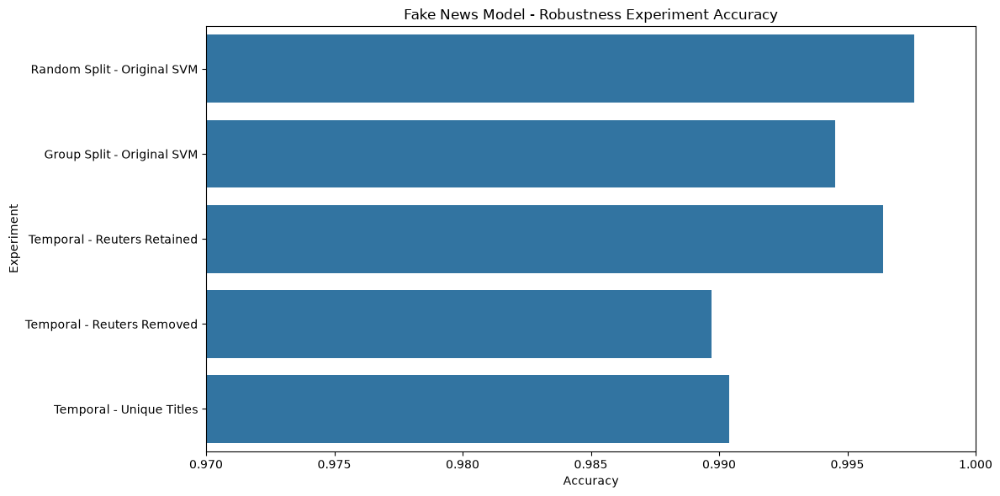

In [209]:
# Visualizing robustness accuracy

plt.figure(figsize=(12, 6))

sns.barplot(
    data=robustness_results,
    x="Accuracy",
    y="Experiment"
)

plt.title("Fake News Model - Robustness Experiment Accuracy")
plt.xlabel("Accuracy")
plt.ylabel("Experiment")
plt.xlim(0.97, 1.00)
plt.tight_layout()
plt.show()

## Model Explainability (XAI)

We'll now investigate what words and phrases our Linear SVM learned to associate with Fake News and Real News.

#### Extract learned feature coefficients

In [210]:
# Getting the most influential words and phrases

tfidf_temporal = temporal_svm_no_reuters.named_steps["tfidf"]

svm_temporal = temporal_svm_no_reuters.named_steps["classifier"]

feature_names = tfidf_temporal.get_feature_names_out()

coefficients = svm_temporal.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance = feature_importance.sort_values(
    by="Coefficient",
    ascending=False
)

display(feature_importance.head(30))

,Feature,Coefficient
14640,said,6.780969
19117,washington,4.616266
12888,presid donald,4.009730
19228,wednesday,2.986907
18282,tuesday,2.855953
12878,presid barack,2.750709
6254,friday,2.370690
17391,thursday,2.314211
11296,nov,2.285772
19128,washington presid,2.272854


In [211]:
# Extracting strongest Fake News-associated features

# Top 30 features associated with Fake News

display(
    feature_importance.sort_values(
        by="Coefficient",
        ascending=True
    ).head(30)
)

,Feature,Coefficient
18756,via,-6.958845
7592,imag,-3.728398
15370,sen,-2.997045
6676,gop,-2.977778
11363,obama,-2.911359
14943,saidth,-2.902880
12946,presid trump,-2.889734
13896,rep,-2.700439
7605,imag via,-2.677382
13559,read,-2.593063


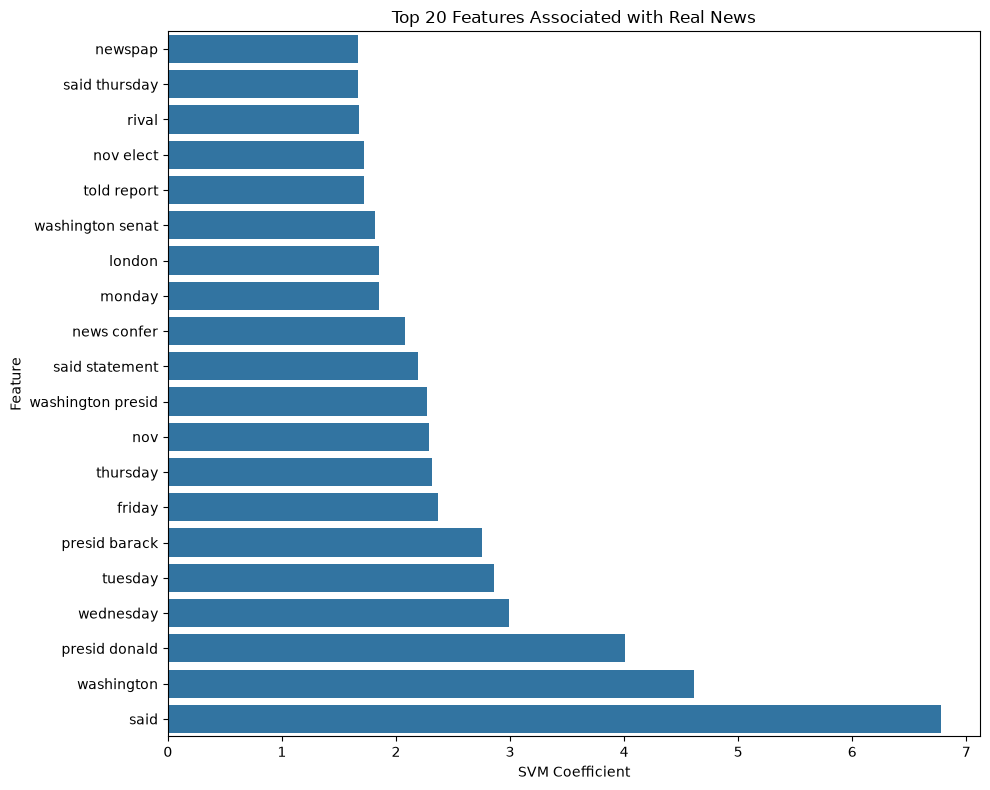

In [212]:
# Visualizing the top influential features

# Plotting top Real News-associated features

top_real_features = feature_importance.head(20).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_real_features,
    x="Coefficient",
    y="Feature"
)

plt.title("Top 20 Features Associated with Real News")
plt.xlabel("SVM Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

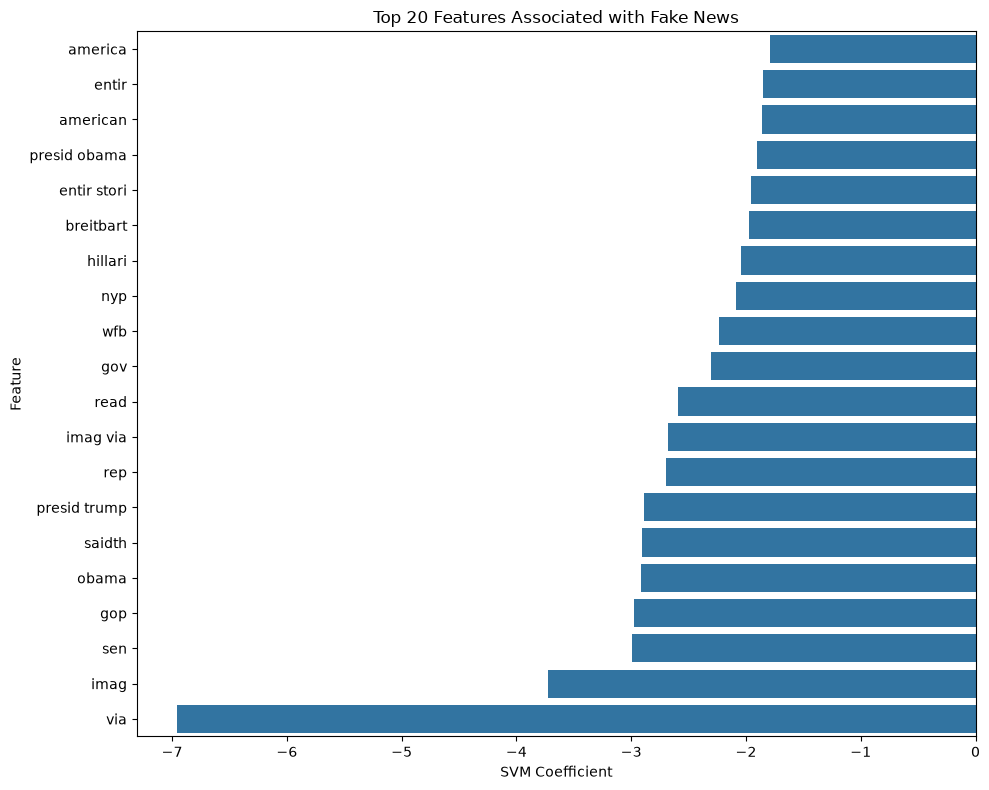

In [213]:
# Plotting top Fake News-associated features

top_fake_features = feature_importance.tail(20).sort_values(
    by="Coefficient",
    ascending=False
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_fake_features,
    x="Coefficient",
    y="Feature"
)

plt.title("Top 20 Features Associated with Fake News")
plt.xlabel("SVM Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Explaining an individual prediction

In [214]:
# Creating an article explanation function

def explain_prediction(text, model, top_n=15):

    tfidf_vectorizer = model.named_steps["tfidf"]
    svm_classifier = model.named_steps["classifier"]

    text_vector = tfidf_vectorizer.transform([text])

    feature_names = tfidf_vectorizer.get_feature_names_out()

    contributions = text_vector.toarray()[0] * svm_classifier.coef_[0]

    explanation = pd.DataFrame({
        "Feature": feature_names,
        "TF-IDF": text_vector.toarray()[0],
        "Coefficient": svm_classifier.coef_[0],
        "Contribution": contributions
    })

    explanation = explanation[
        explanation["TF-IDF"] > 0
    ].copy()

    explanation["Direction"] = np.where(
        explanation["Contribution"] > 0,
        "Real News",
        "Fake News"
    )

    fake_contributions = explanation.sort_values(
        by="Contribution",
        ascending=True
    ).head(top_n)

    real_contributions = explanation.sort_values(
        by="Contribution",
        ascending=False
    ).head(top_n)

    decision_score = model.decision_function([text])[0]

    prediction = model.predict([text])[0]

    print("Predicted label:", prediction)
    print("Prediction:", "Real News" if prediction == 1 else "Fake News")
    print("Decision score:", decision_score)

    print("\nFeatures pushing toward Fake News:")
    display(fake_contributions)

    print("\nFeatures pushing toward Real News:")
    display(real_contributions)

    return explanation

## Explaining a real test article

In [215]:
# Selecting one article from the temporal test set

sample_article = temporal_test_unique.sample(
    n=1, random_state=42
).iloc[0]

print("Title:", sample_article["title"])
print("Actual label:", "Real News" if sample_article["label"] == 1 else "Fake News")
print("\nArticle text:")
print(sample_article["text"][:1500])

Title: London will remain leading financial center: PM May's spokesman
Actual label: Real News

Article text:
LONDON (Reuters) - London will remain the world s leading financial center, a spokesman for British Prime Minister Theresa May said on Thursday when asked about comments by Goldman Sachs chief executive Lloyd Blankfein.   We re not going to comment on each individual statement but lets be clear, London is and will remain the world s leading financial center,  the spokesman said when asked about a tweet in which Blankfein said he was planning to spend more time in Frankfurt - a rival financial center. 


In [216]:
# Expalining the model's prediction 

article_explanation = explain_prediction(
    sample_article["clean_text_no_reuters"],
    temporal_svm_no_reuters,
    top_n=15
)

Predicted label: 1
Prediction: Real News
Decision score: 2.028640467883508

Features pushing toward Fake News:


,Feature,TF-IDF,Coefficient,Contribution,Direction
9245,lloyd,0.178923,-0.416667,-0.074551,Fake News
14617,sach,0.144876,-0.505432,-0.073225,Fake News
9035,let,0.076709,-0.853610,-0.065479,Fake News
2787,clear,0.075961,-0.705259,-0.053572,Fake News
17425,time,0.048772,-0.987961,-0.048185,Fake News
6582,go,0.061529,-0.644741,-0.039670,Fake News
19595,world,0.117324,-0.299779,-0.035171,Fake News
7801,individu,0.091932,-0.269556,-0.024781,Fake News
12481,plan,0.066219,-0.336971,-0.022314,Fake News
13038,prime,0.098167,-0.165201,-0.016217,Fake News



Features pushing toward Real News:


,Feature,TF-IDF,Coefficient,Contribution,Direction
14640,said,0.071196,6.780969,0.482778,Real News
9282,london,0.249697,1.850884,0.462160,Real News
16180,spokesman,0.146986,1.417814,0.208399,Real News
14904,said thursday,0.111747,1.667219,0.186308,Real News
14350,rival,0.102579,1.677879,0.172115,Real News
17391,thursday,0.073779,2.314211,0.170740,Real News
2601,chief execut,0.122382,1.286686,0.157467,Real News
3067,comment,0.119374,1.297635,0.154904,Real News
10171,minist,0.085675,1.390170,0.119103,Real News
1944,british,0.114068,0.769255,0.087748,Real News


## Explaining an incorrectly classified article

In [217]:
# Selecting a misclassified fake article

fake_error_unique = (
    fake_predicted_real
    .drop_duplicates(subset="title")
)

sample_fake_error = fake_error_unique.iloc[0]

print("Title:", sample_fake_error["title"])
print("Actual label:", sample_fake_error["label"])
print("Predicted label:", sample_fake_error["predicted_label"])
print("\nArticle text:")
print(sample_fake_error["text"][:1500])

Title: BREAKING: BROTHER Of Las Vegas Massacre Suspect Has Been ARRESTED In California
Actual label: 0
Predicted label: 1

Article text:
By now, most of America has seen the crazy video of the Las Vegas mass shooter s brother Eric Paddock. Stephen Paddock s brother Eric, defended his brother, by arguing that he was wealthy and that somehow because he was generous to him and his mother, (which he bragged about ad nauseam) that people should consider looking at his brother in a different light.Watch this compilation of Stephen Paddock s brother Eric Paddock s strangest moments during the interview:The family of the alleged mass murderer Stephen Paddock is very interesting, to say the least. Stephen s father was listed on the FBI s  Most Wanted  list, and now, it appears, there s another alleged criminal in the Paddock family.A brother of Las Vegas mass shooter Stephen Paddock was arrested in Los Angeles on Wednesday on suspicion of possessing hundreds of images of child pornography, acco

In [218]:
# Explaining its prediction

fake_error_explanation = explain_prediction(
    sample_fake_error["clean_text_no_reuters"],
    temporal_svm_no_reuters,
    top_n=15
)

Predicted label: 1
Prediction: Real News
Decision score: 0.17288584703659393

Features pushing toward Fake News:


,Feature,TF-IDF,Coefficient,Contribution,Direction
7592,imag,0.053570,-3.728398,-0.199729,Fake News
18719,vega,0.173335,-0.390595,-0.067704,Fake News
5637,fbi,0.088603,-0.750907,-0.066532,Fake News
3741,crimin,0.086120,-0.638465,-0.054985,Fake News
3587,counti,0.079537,-0.690370,-0.054910,Fake News
632,america,0.028612,-1.787445,-0.051143,Fake News
8682,la,0.172841,-0.280166,-0.048424,Fake News
16742,sun,0.066331,-0.686231,-0.045518,Fake News
10821,news,0.025765,-1.744698,-0.044952,Fake News
18807,video,0.032393,-1.361961,-0.044118,Fake News



Features pushing toward Real News:


,Feature,TF-IDF,Coefficient,Contribution,Direction
14640,said,0.031486,6.780969,0.213507,Real News
19228,wednesday,0.054509,2.986907,0.162814,Real News
18282,tuesday,0.031259,2.855953,0.089273,Real News
14888,said statement,0.039366,2.197207,0.086494,Real News
16192,spokeswoman,0.079662,0.900374,0.071726,Real News
206,ad,0.054033,1.317354,0.071181,Real News
11896,paddock,0.389453,0.180435,0.070271,Real News
4072,declin,0.071128,0.964403,0.068596,Real News
3067,comment,0.052793,1.297635,0.068506,Real News
4073,declin comment,0.091142,0.668540,0.060932,Real News


#### Comparing correct and incorrect predictions

In [219]:
# Creating an explainability comparison

comparison = pd.DataFrame([
    {
        "Article": "Correct Real News",
        "Actual": "Real",
        "Predicted": "Real",
        "Decision Score": 2.028640
    },
    {
        "Article": "Incorrect Fake News",
        "Actual": "Fake",
        "Predicted": "Real",
        "Decision Score": 0.172886
    }
])

display(comparison)

,Article,Actual,Predicted,Decision Score
0,Correct Real News,Real,Real,2.028640
1,Incorrect Fake News,Fake,Real,0.172886


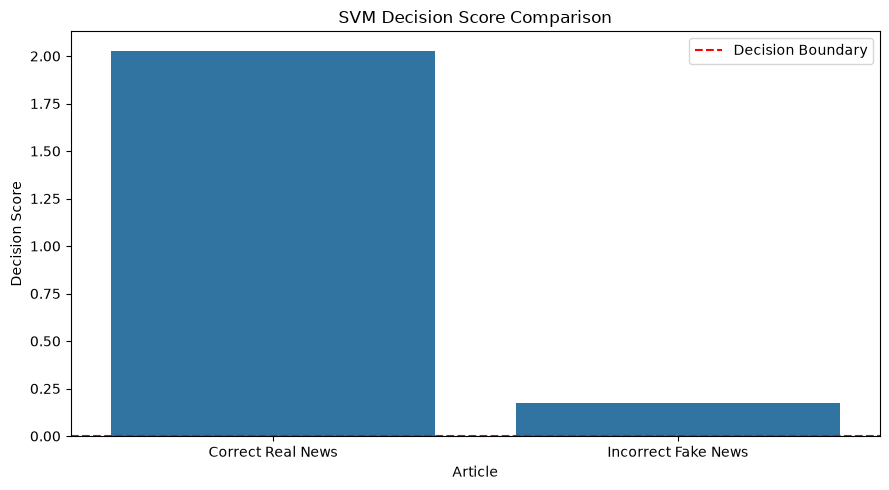

In [220]:
# Visualizing decision scores

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison,
    x="Article",
    y="Decision Score"
)

plt.axhline(
    y=0,
    linestyle="--",
    color="red",
    label="Decision Boundary"
)

plt.title("SVM Decision Score Comparison")
plt.ylabel("Decision Score")
plt.xlabel("Article")
plt.legend()

plt.tight_layout()
plt.show()

## Probability Calibration

In [221]:
# Linear SVM produces decision scores, not probabilities.
# Using CalibratedClassifierCV to convert decision scores into estimated probabilities

In [222]:
# Importing calibration tools

from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split

In [223]:
# Creating a calibration dataset

X_cal_train, X_cal_valid, y_cal_train, y_cal_valid = train_test_split(
    temporal_train_clean["clean_text_no_reuters"],
    temporal_train_clean["label"],
    test_size=0.20,
    random_state=42,
    stratify=temporal_train_clean["label"]
)

print("Model training samples:", len(X_cal_train))
print("Calibration validation samples:", len(X_cal_valid))


Model training samples: 28098
Calibration validation samples: 7025


In [224]:
# Creating a calibration pipeline 

from sklearn.calibration import CalibratedClassifierCV

base_svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

calibrated_svm = CalibratedClassifierCV(
    estimator=base_svm_pipeline,
    method="sigmoid",
    cv=5
)

In [225]:
# Training the calibrated model

calibrated_svm.fit(
    X_cal_train,
    y_cal_train
)

print("Calibrated SVM training completed.")

Calibrated SVM training completed.


In [226]:
# Generating validation probabilities

y_cal_proba = calibrated_svm.predict_proba(X_cal_valid)

y_cal_pred = calibrated_svm.predict(X_cal_valid)

print("Probability matrix shape:", y_cal_proba.shape)
print("First 10 Fake probabilities:")
print(y_cal_proba[:10, 0])

print("\nFirst 10 Real probabilities:")
print(y_cal_proba[:10, 1])

Probability matrix shape: (7025, 2)
First 10 Fake probabilities:
[9.99968702e-01 9.99266208e-01 9.98874190e-01 9.97398246e-01
 9.99384708e-01 9.99978370e-01 9.99993322e-01 5.81067975e-05
 1.04400490e-03 9.76747641e-01]

First 10 Real probabilities:
[3.12977842e-05 7.33792339e-04 1.12580996e-03 2.60175410e-03
 6.15292445e-04 2.16300458e-05 6.67752550e-06 9.99941893e-01
 9.98955995e-01 2.32523585e-02]


In [227]:
# Checking probability totals

print("Probability sums for first 10 articles:")
print(y_cal_proba[:10].sum(axis=1))

Probability sums for first 10 articles:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


#### Understanding calibrated probabilities

In [228]:
# Evaluating probability calibration

# Calculating Brier score and Log Loss

from sklearn.metrics import brier_score_loss, log_loss

brier = brier_score_loss(
    y_cal_valid,
    y_cal_proba[:, 1]
)

logloss = log_loss(
    y_cal_valid,
    y_cal_proba
)

print("Brier Score:", brier)
print("Log Loss:", logloss)

Brier Score: 0.007288854261352111
Log Loss: 0.02912051700945997


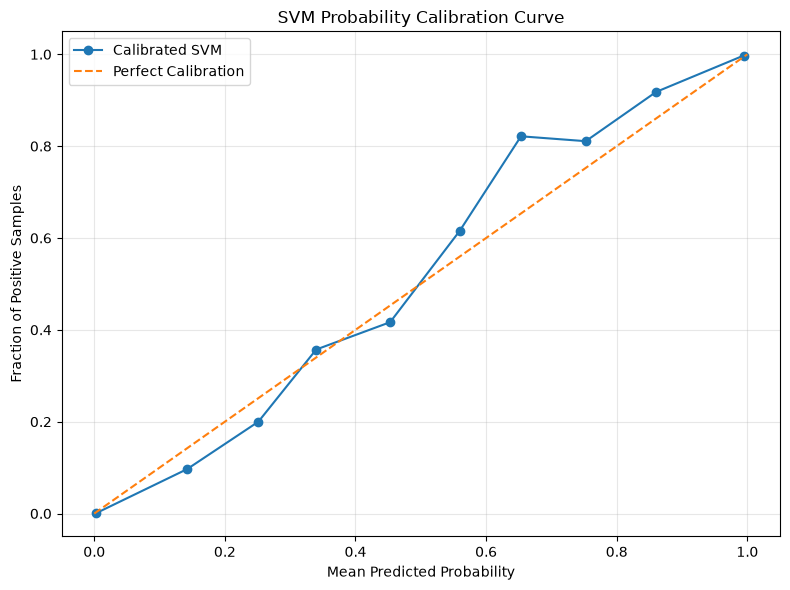

In [229]:
# Plotting the reliability diagram

from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_cal_valid,
    y_cal_proba[:, 1],
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Calibrated SVM"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positive Samples")
plt.title("SVM Probability Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [230]:
# Evaluating classification performance after calibration

print("Calibrated SVM Accuracy:",
      accuracy_score(y_cal_valid, y_cal_pred))

print("Calibrated SVM Precision:",
      precision_score(y_cal_valid, y_cal_pred))

print("Calibrated SVM Recall:",
      recall_score(y_cal_valid, y_cal_pred))

print("Calibrated SVM F1:",
      f1_score(y_cal_valid, y_cal_pred))

print("\nClassification Report:")

print(classification_report(
    y_cal_valid,
    y_cal_pred,
    target_names=["Fake News", "Real News"]
))

Calibrated SVM Accuracy: 0.9911743772241993
Calibrated SVM Precision: 0.9894353369763206
Calibrated SVM Recall: 0.9879956347762823
Calibrated SVM F1: 0.9887149617764834

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.99      0.99      0.99      4276
   Real News       0.99      0.99      0.99      2749

    accuracy                           0.99      7025
   macro avg       0.99      0.99      0.99      7025
weighted avg       0.99      0.99      0.99      7025



#### Final temporal evaluation of calibrated SVM

In [231]:
# Training the final calibrated SVM

final_calibrated_svm = CalibratedClassifierCV(
    estimator=base_svm_pipeline,
    method="sigmoid",
    cv=5
)

final_calibrated_svm.fit(
    temporal_train_clean["clean_text_no_reuters"],
    temporal_train_clean["label"]
)

print("Final calibrated SVM training completed.")

Final calibrated SVM training completed.


In [232]:
# Predicting future news and obtain probabilities

y_final_temporal_pred = final_calibrated_svm.predict(
    temporal_test["clean_text_no_reuters"]
)

y_final_temporal_proba = final_calibrated_svm.predict_proba(
    temporal_test["clean_text_no_reuters"]
)

y_final_temporal_true = temporal_test["label"]

print("Probability matrix shape:", y_final_temporal_proba.shape)
print("First 10 predictions:", y_final_temporal_pred[:10])
print("First 10 Real probabilities:", y_final_temporal_proba[:10, 1])

Probability matrix shape: (8848, 2)
First 10 predictions: [1 0 1 0 1 1 1 1 1 1]
First 10 Real probabilities: [9.99374326e-01 1.06017095e-03 9.99980757e-01 9.69001804e-04
 9.75873459e-01 9.62125085e-01 9.99993792e-01 9.83359276e-01
 9.96229622e-01 9.92206073e-01]


In [233]:
# Evaluating final calibrated performance

print("FINAL CALIBRATED TEMPORAL RESULTS")

print("Accuracy:",
      accuracy_score(y_final_temporal_true, y_final_temporal_pred))

print("Precision:",
      precision_score(y_final_temporal_true, y_final_temporal_pred))

print("Recall:",
      recall_score(y_final_temporal_true, y_final_temporal_pred))

print("F1 Score:",
      f1_score(y_final_temporal_true, y_final_temporal_pred))

print("Brier Score:",
      brier_score_loss(
          y_final_temporal_true,
          y_final_temporal_proba[:, 1]
      ))

print("Log Loss:",
      log_loss(
          y_final_temporal_true,
          y_final_temporal_proba
      ))

print("\nClassification Report:")

print(classification_report(
    y_final_temporal_true,
    y_final_temporal_pred,
    target_names=["Fake News", "Real News"]
))

print("\nConfusion Matrix:")

print(confusion_matrix(
    y_final_temporal_true,
    y_final_temporal_pred
))

FINAL CALIBRATED TEMPORAL RESULTS
Accuracy: 0.9897151898734177
Precision: 0.9963651050080775
Recall: 0.9914266577361018
F1 Score: 0.9938897468609413
Brier Score: 0.009889092762642325
Log Loss: 0.041953500661361436

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.95      0.98      0.97      1383
   Real News       1.00      0.99      0.99      7465

    accuracy                           0.99      8848
   macro avg       0.98      0.99      0.98      8848
weighted avg       0.99      0.99      0.99      8848


Confusion Matrix:
[[1356   27]
 [  64 7401]]


#### Analyzing prediction confidence

In [234]:
# Creating a confidence analysis dataset

confidence_df = temporal_test.copy()

confidence_df["predicted_label"] = y_final_temporal_pred

confidence_df["fake_probability"] = (
    y_final_temporal_proba[:, 0]
)

confidence_df["real_probability"] = (
    y_final_temporal_proba[:, 1]
)

confidence_df["confidence"] = (
    y_final_temporal_proba.max(axis=1)
)

confidence_df["correct"] = (
    confidence_df["label"] == confidence_df["predicted_label"]
)

confidence_df["prediction"] = np.where(
    confidence_df["predicted_label"] == 1,
    "Real News",
    "Fake News"
)

display(
    confidence_df[
        [
            "title",
            "label",
            "prediction",
            "fake_probability",
            "real_probability",
            "confidence",
            "correct"
        ]
    ].head(10)
)

,title,label,prediction,fake_probability,real_probability,confidence,correct
35124,Russia says Trump stance on Iran deal 'extreme...,1,Real News,0.000626,0.999374,0.999374,True
35125,"ACTRESS ACCUSES Weinstein Buddy, Actor GEORGE ...",0,Fake News,0.998940,0.001060,0.998940,True
35126,UK's Johnson to visit Moscow this year to disc...,1,Real News,0.000019,0.999981,0.999981,True
35127,BUSTED! FBI Hid Clinton-Lynch Tarmac Meeting D...,0,Fake News,0.999031,0.000969,0.999031,True
35128,Trump says he has decided to decertify Iran nu...,1,Real News,0.024127,0.975873,0.975873,True
35129,Israeli minister says Trump speech may start w...,1,Real News,0.037875,0.962125,0.962125,True
35130,'Time is running out:' Germany urges UK to mov...,1,Real News,0.000006,0.999994,0.999994,True
35131,Norway plans to send armored unit close to Rus...,1,Real News,0.016641,0.983359,0.983359,True
35132,Trump says Democratic leaders should come to W...,1,Real News,0.003770,0.996230,0.996230,True
35133,Russia questions future of Syria chemical weap...,1,Real News,0.007794,0.992206,0.992206,True


In [235]:
# Analyzing confidence distribution

print("Average confidence:",
      confidence_df["confidence"].mean())

print("\nConfidence distribution:")

display(
    confidence_df["confidence"].describe()
)

Average confidence: 0.9749863439745199

Confidence distribution:


count    8848.000000
mean        0.974986
std         0.067168
min         0.501784
25%         0.987303
50%         0.997923
75%         0.999644
max         1.000000
Name: confidence, dtype: float64

In [236]:
# Categorizing prediction confidence

confidence_df["confidence_level"] = pd.cut(
    confidence_df["confidence"],
    bins=[0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    labels=[
        "50-60%",
        "60-70%",
        "70-80%",
        "80-90%",
        "90-100%"
    ],
    include_lowest=True
)

display(
    confidence_df["confidence_level"].value_counts(
        sort=False
    )
)

confidence_level
50-60%       74
60-70%      102
70-80%      149
80-90%      308
90-100%    8215
Name: count, dtype: int64

In [237]:
# Calculating confidence-wise accuracy

confidence_analysis = (
    confidence_df.groupby("confidence_level", observed=False)
    .agg(
        total_articles=("correct", "count"),
        correct_predictions=("correct", "sum"),
        accuracy=("correct", "mean")
    )
)

confidence_analysis["error_rate"] = (
    1 - confidence_analysis["accuracy"]
)

display(confidence_analysis)

,total_articles,correct_predictions,accuracy,error_rate
confidence_level,,,,
50-60%,74,49,0.662162,0.337838
60-70%,102,83,0.813725,0.186275
70-80%,149,134,0.899329,0.100671
80-90%,308,293,0.951299,0.048701
90-100%,8215,8198,0.997931,0.002069


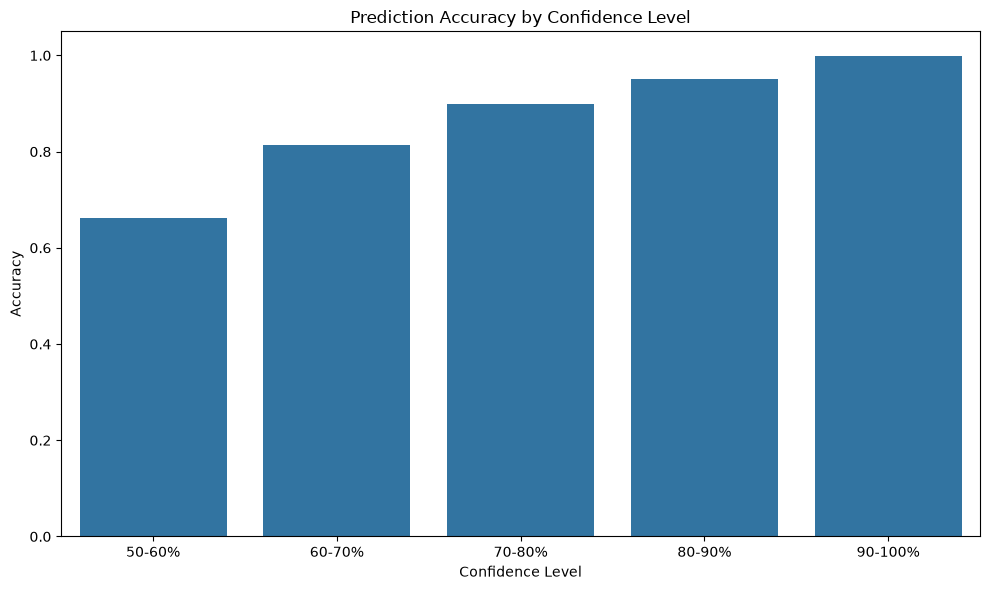

In [238]:
# Visualizing accuracy by confidence

plt.figure(figsize=(10, 6))

sns.barplot(
    data=confidence_analysis.reset_index(),
    x="confidence_level",
    y="accuracy"
)

plt.title("Prediction Accuracy by Confidence Level")
plt.xlabel("Confidence Level")
plt.ylabel("Accuracy")

plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [239]:
# Identifying high-confidence mistakes

high_confidence_errors = confidence_df[
    (confidence_df["correct"] == False) &
    (confidence_df["confidence"] >= 0.90)
].copy()

print("Total high-confidence errors:",
      len(high_confidence_errors))

print("\nHigh-confidence Fake predicted as Real:",
      len(high_confidence_errors[
          (high_confidence_errors["label"] == 0) &
          (high_confidence_errors["predicted_label"] == 1)
      ]))

print("\nHigh-confidence Real predicted as Fake:",
      len(high_confidence_errors[
          (high_confidence_errors["label"] == 1) &
          (high_confidence_errors["predicted_label"] == 0)
      ]))

display(
    high_confidence_errors[
        [
            "title",
            "label",
            "prediction",
            "confidence",
            "fake_probability",
            "real_probability"
        ]
    ].head(15)
)

Total high-confidence errors: 17

High-confidence Fake predicted as Real: 7

High-confidence Real predicted as Fake: 10


,title,label,prediction,confidence,fake_probability,real_probability
35639,INTERNET: Living with the Great Firewall of China,1,Fake News,0.970436,0.970436,0.029564
35663,GENERATION GAP: China's one-child generation g...,1,Fake News,0.934172,0.934172,0.065828
35713,POLITICS: Xi Jinping's compliant generation,1,Fake News,0.982049,0.982049,0.017951
37636,A Picture and its Story: Reaching out to rescu...,1,Fake News,0.985757,0.985757,0.014243
38545,"In a corner of a French field, memories of U.S...",1,Fake News,0.919423,0.919423,0.080577
38711,Hackers play 30 minutes of Islamic State propa...,1,Fake News,0.936778,0.936778,0.063222
39688,Zimbabwe war vets threaten to unleash crowds o...,1,Fake News,0.953164,0.953164,0.046836
40506,Reaction to Prince Harry's engagement to Megha...,1,Fake News,0.905383,0.905383,0.094617
41855,JUST IN: OBAMA APPOINTED JUDGE Presiding Over ...,0,Real News,0.941676,0.058324,0.941676
41925,JUST IN: OBAMA APPOINTED JUDGE Presiding Over ...,0,Real News,0.941676,0.058324,0.941676


#### Analyzing high-confidence errors by class

In [240]:
# Counting high-confidence errors

print("Total high-confidence errors:", len(high_confidence_errors))

print("\nError breakdown:")

display(
    high_confidence_errors["prediction"].value_counts()
)

print("\nActual label distribution:")

display(
    high_confidence_errors["label"].value_counts()
)


Total high-confidence errors: 17

Error breakdown:


prediction
Fake News    10
Real News     7
Name: count, dtype: int64


Actual label distribution:


label
1    10
0     7
Name: count, dtype: int64

In [241]:
# Checking duplicate high-confidence errors

print(
    "High-confidence error rows:",
    len(high_confidence_errors)
)

print(
    "Unique error titles:",
    high_confidence_errors["title"].nunique()
)

print(
    "Duplicate error rows:",
    len(high_confidence_errors)
    - high_confidence_errors["title"].nunique()
)

High-confidence error rows: 17
Unique error titles: 14
Duplicate error rows: 3


In [242]:
# Displaying the most confident mistakes

display(
    high_confidence_errors.sort_values(
        by="confidence",
        ascending=False
    )[
        [
            "title",
            "parsed_date",
            "label",
            "prediction",
            "confidence"
        ]
    ]
)

,title,parsed_date,label,prediction,confidence
42284,Pictures of the Year: A picture and its story,2017-12-11,1,Fake News,0.996001
42721,WATCH: PRESIDENT TRUMP CHANNELS Successful Dev...,2017-12-14,0,Real News,0.994192
42685,WATCH: PRESIDENT TRUMP CHANNELS Successful Dev...,2017-12-14,0,Real News,0.994192
37636,A Picture and its Story: Reaching out to rescu...,2017-11-02,1,Fake News,0.985757
35713,POLITICS: Xi Jinping's compliant generation,2017-10-17,1,Fake News,0.982049
43890,WHAT THE U.S. Would Save If Trump Cut Aid To U...,2017-12-29,0,Real News,0.980958
35639,INTERNET: Living with the Great Firewall of China,2017-10-17,1,Fake News,0.970436
43806,ISRAEL WILL NAME New Train Station Near Wester...,2017-12-27,0,Real News,0.962825
43833,ISRAEL WILL NAME New Train Station Near Wester...,2017-12-27,0,Real News,0.962825
39688,Zimbabwe war vets threaten to unleash crowds o...,2017-11-19,1,Fake News,0.953164


In [243]:
# Evaluating a 90% confidence threshold

confidence_threshold = 0.90

confidence_df["final_decision"] = np.where(
    confidence_df["confidence"] >= confidence_threshold,
    confidence_df["prediction"],
    "Manual Review"
)

print("Decision distribution:")

display(
    confidence_df["final_decision"].value_counts()
)

accepted_predictions = confidence_df[
    confidence_df["final_decision"] != "Manual Review"
]

print("\nCoverage:",
      len(accepted_predictions) / len(confidence_df))

print("Accuracy among accepted predictions:",
      accepted_predictions["correct"].mean())

print("Manual review required:",
      (confidence_df["final_decision"] == "Manual Review").sum())

Decision distribution:


final_decision
Real News        6931
Fake News        1284
Manual Review     633
Name: count, dtype: int64


Coverage: 0.9284584086799277
Accuracy among accepted predictions: 0.997930614729154
Manual review required: 633


In [244]:
# Comparing different confidence thresholds

threshold_results = []

for threshold in [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99]:

    accepted = confidence_df[
        confidence_df["confidence"] >= threshold
    ]

    threshold_results.append({
        "Threshold": threshold,
        "Accepted Articles": len(accepted),
        "Coverage": len(accepted) / len(confidence_df),
        "Accuracy": accepted["correct"].mean(),
        "Errors": (~accepted["correct"]).sum()
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df)

,Threshold,Accepted Articles,Coverage,Accuracy,Errors
0,0.50,8848,1.000000,0.989715,91
1,0.60,8774,0.991637,0.992478,66
2,0.70,8672,0.980108,0.994580,47
3,0.80,8523,0.963269,0.996245,32
4,0.90,8215,0.928458,0.997931,17
5,0.95,7812,0.882911,0.998720,10
6,0.99,6410,0.724458,0.999532,3


### Choosing a confidence threshold using validation data

In [245]:
# Preparing validation confidence data

validation_confidence = pd.DataFrame({
    "actual": y_cal_valid,
    "predicted": y_cal_pred,
    "confidence": y_cal_proba.max(axis=1)
})

validation_confidence["correct"] = (
    validation_confidence["actual"]
    == validation_confidence["predicted"]
)

In [246]:
# Comparing thresholds on validation data

validation_threshold_results = []

for threshold in [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99]:

    accepted = validation_confidence[
        validation_confidence["confidence"] >= threshold
    ]

    validation_threshold_results.append({
        "Threshold": threshold,
        "Accepted Articles": len(accepted),
        "Coverage": len(accepted) / len(validation_confidence),
        "Selective Accuracy": accepted["correct"].mean(),
        "Errors": (~accepted["correct"]).sum()
    })

validation_threshold_df = pd.DataFrame(
    validation_threshold_results
)

display(validation_threshold_df)

,Threshold,Accepted Articles,Coverage,Selective Accuracy,Errors
0,0.50,7025,1.000000,0.991174,62
1,0.60,6988,0.994733,0.993274,47
2,0.70,6946,0.988754,0.994673,37
3,0.80,6874,0.978505,0.996654,23
4,0.90,6751,0.960996,0.998222,12
5,0.95,6612,0.941210,0.998488,10
6,0.99,6075,0.864769,0.999506,3


### Applying the selected threshold

In [247]:
# Setting the threshold
CONFIDENCE_THRESHOLD = 0.90

In [248]:
# Applying it to the temporal test predictions

final_test_results = confidence_df.copy()

final_test_results["final_decision"] = np.where(
    final_test_results["confidence"] >= CONFIDENCE_THRESHOLD,
    final_test_results["prediction"],
    "Manual Review"
)

display(
    final_test_results["final_decision"].value_counts()
)

final_decision
Real News        6931
Fake News        1284
Manual Review     633
Name: count, dtype: int64

In [249]:
# Evaluating selective prediction

accepted_test = final_test_results[
    final_test_results["final_decision"] != "Manual Review"
]

manual_review_test = final_test_results[
    final_test_results["final_decision"] == "Manual Review"
]

print("Confidence threshold:", CONFIDENCE_THRESHOLD)

print("Total articles:", len(final_test_results))

print("Automatically classified:", len(accepted_test))

print("Sent for manual review:", len(manual_review_test))

print("Coverage:",
      len(accepted_test) / len(final_test_results))

print("Selective accuracy:",
      accepted_test["correct"].mean())

print("Incorrect automatic predictions:",
      (~accepted_test["correct"]).sum())

Confidence threshold: 0.9
Total articles: 8848
Automatically classified: 8215
Sent for manual review: 633
Coverage: 0.9284584086799277
Selective accuracy: 0.997930614729154
Incorrect automatic predictions: 17


## Model Saving and Deployment preparation

In [250]:
# Saving the trained model

# Import joblib and create the models directory

import os
import joblib

os.makedirs("../models", exist_ok=True)

In [251]:
# Saving the model and prediction settings

model_package = {
    "model": final_calibrated_svm,
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "label_mapping": {
        0: "Fake News",
        1: "Real News"
    }
}

joblib.dump(
    model_package,
    "../models/fake_news_detector.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [252]:
# Verifying the saved model

saved_model = joblib.load(
    "../models/fake_news_detector.joblib"
)

print("Model loaded successfully.")

print("Confidence threshold:",
      saved_model["confidence_threshold"])

print("Label mapping:",
      saved_model["label_mapping"])

print("Model type:",
      type(saved_model["model"]))

Model loaded successfully.
Confidence threshold: 0.9
Label mapping: {0: 'Fake News', 1: 'Real News'}
Model type: <class 'sklearn.calibration.CalibratedClassifierCV'>


## Building the web application

In [253]:
pip install streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [254]:
# Create models directory if it does not exist
os.makedirs("models", exist_ok=True)

# Package the trained model and its configuration
model_package = {
    "model": final_calibrated_svm,
    "confidence_threshold": CONFIDENCE_THRESHOLD,
    "label_mapping": {
        0: "Fake News",
        1: "Real News"
    }
}

# Save the model
joblib.dump(
    model_package,
    "models/fake_news_detector.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [255]:
# Verifying the saved model

# Check whether the model file exists
model_path = "models/fake_news_detector.joblib"

print("Model file exists:", os.path.exists(model_path))

# Load the saved model
saved_model = joblib.load(model_path)

# Extract model components
loaded_model = saved_model["model"]
loaded_threshold = saved_model["confidence_threshold"]
loaded_labels = saved_model["label_mapping"]

print("\nModel loaded successfully!")
print("Model type:", type(loaded_model))
print("Confidence threshold:", loaded_threshold)
print("Label mapping:", loaded_labels)

Model file exists: True

Model loaded successfully!
Model type: <class 'sklearn.calibration.CalibratedClassifierCV'>
Confidence threshold: 0.9
Label mapping: {0: 'Fake News', 1: 'Real News'}


In [ ]:
# Testing fake article from the dataset in Streamlit app

fake_data = pd.read_csv("../data/Fake.csv")

sample_fake = fake_data.sample(
    n=1,
    random_state=42
).iloc[0]

print("TITLE:")
print(sample_fake["title"])

print("\nARTICLE BODY:")
print(sample_fake["text"])

TITLE:
ABOUT HILLARY’S COUGH: We Discovered The Secret To Why She Keeps Coughing [Video]

ARTICLE BODY:
 


In [257]:
# Testing Sensational or misleading article in Streamlit app

sensational = fake_data[
    fake_data["title"].str.contains(
        r"BREAKING|SHOCKING|EXPOSED|BOMBSHELL|MUST SEE|JUST IN|WOW",
        case=False,
        na=False
    )
]

if not sensational.empty:
    sample_sensational = sensational.iloc[0]

    print("TITLE:")
    print(sample_sensational["title"])

    print("\nARTICLE BODY:")
    print(sample_sensational["text"])
else:
    print("No matching sensational headline found.")


TITLE:
 BREAKING: Cop Finally Gets His Due, Walter Scott’s Killer Sentenced To Prison (DETAILS)

ARTICLE BODY:
In America, we have been having a conversation about police brutality against black Americans. Despite the countless black people murdered unjustly by police, there is usually no justice. Sandra Bland, Philando Castile, Keith Lamont Scott, Michael Brown, Freddie Gray too many to mention here, really. All of those people were senselessly murdered by cops who chose to be their judges, juries, and executioners, and they did so with impunity and without consequence. However, there is hope, and it is coming out of South Carolina, of all places.North Charleston police officer Michael Slager murdered Walter Scott, a black man who was fleeing after a routine traffic stop in cold blood in 2015. He would have gotten away with it, too, had it not been for a citizen who was brave enough to tape the murder. The tape showed that Slager had lied about his life being in danger, and it showed 